# Does Benford's law fit the leading digits of world-country populations?

**Evaluation artifact → runnable demo.** This notebook reproduces the central machinery of an
evaluation of a *Benford screen* on country populations: it asks how closely the first significant
digits of world-country populations follow Benford's law $p_d = \log_{10}(1 + 1/d)$, and — more
importantly — it asks that question **with the null the data actually have**.

The panel is 100 countries observed yearly from 1950 to 2023 (7,400 country-years). The artifact's
full run uses 236 countries × 74 years (17,464 rows); the subset in `mini_demo_data.json` is drawn at
log-spaced quantiles of mean population, so it spans microstates (Vatican City, ~500 people) through
China (~1.4 billion).

### The methodological point this artifact makes

The literature's usual test is a Pearson $\chi^2$ against exact Benford at the nominal row count $n$.
Country populations are a **panel**: each country is observed ~74 times, and a country's mantissa
$\log_{10}$ stays almost fixed relative to the spread across countries. The nominal $n$ therefore
overstates the independent information by roughly the number of years per country — a design effect
near 9. The naive test then rejects Benford for essentially any real panel, and its $p$-value means
nothing. This notebook computes, side by side:

* five conformity readouts — MAD, sup-distance $M$, $|c_1|$ (the first circular harmonic of the
  mantissa), $\chi^2$, Kuiper $V$;
* their $p$-values under a **cluster-calibrated** exact-Benford null (one Benford mantissa per
  country, then that country's own years wandering at the measured within-country amplitude);
* their $p$-values under the **naive i.i.d.** null that the usual $\chi^2$ implicitly assumes;
* an **entity-level** check at one draw per country ($n$ = number of countries), the correctly
  powered snapshot;
* a **rival size law** fitted on the even years and carried to the reserved odd years
  (lognormal, 2- and 3-component lognormal mixtures, double Pareto-lognormal, truncated power law),
  with a reserved-fold confirmation statistic $M$ and its matched-null envelope;
* a **two-null discrimination** test: can 100 countries' digits tell exact Benford from the fitted
  size law at all?

Every number below is computed here from the raw published populations in `mini_demo_data.json`.
Nothing is hard-coded, so the printed table is a genuine (smaller-$n$) run of the same recipe.

## 1. Install dependencies

Everything this notebook needs — `numpy`, `pandas`, `scipy`, `matplotlib` — is pre-installed on
Colab. Installing any of them there would overwrite C extensions that are already loaded, so the
pinned versions are installed **only** when `google.colab` is absent (i.e. in a local Jupyter).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# numpy, pandas, scipy, matplotlib are pre-installed on Colab: skip them there and
# install Colab's exact versions locally so this run mirrors the Colab environment.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

## 2. Imports and figure style

The original `eval.py` imports `numpy`, `pandas`, `loguru` and its own modules (`benford_core`,
`calibrated`, `size_laws`, `null_models`, `panel`, `stages_*`). Those modules are reproduced as cells
further down, so the equivalent imports here are the standard scientific stack plus `matplotlib` for
the closing figure.

In [2]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Iterable

import numpy as np
import pandas as pd
from scipy import integrate, optimize, special, stats
from scipy import stats as sstats

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#CC78BC",  # the first further comparator
    "other_2": "#CA9161",  # the second
    "other_3": "#DE8F05",  # the third
    "other_4": "#029E73",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

## 3. Load the data (GitHub URL with a local fallback)

`mini_demo_data.json` holds the curated 100-country slice. Only the **raw published population** is
stored per country-year; the notebook recomputes $\log_{10}$ population, the mantissa and the first
digit under the artifact's own rule (first significant digit of the published figure, base 10, no
truncation).

The loader tries the published GitHub URL first and falls back to the copy sitting beside the
notebook, so the notebook works locally before deployment and in Colab afterwards.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-b2a009-benfords-law-as-a-mixture-microscope/main/round-1/evaluation-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(json.dumps({k: meta[k] for k in ("dataset", "n_countries", "years", "n_rows",
                                       "n_even_rows", "n_odd_rows")}, indent=2))
print("panel rows loaded:", len(data["panel"]))
print("first row:", data["panel"][0])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{
  "dataset": "owid_population_unwpp",
  "n_countries": 100,
  "years": [
    1950,
    2023
  ],
  "n_rows": 7400,
  "n_even_rows": 3700,
  "n_odd_rows": 3700
}
panel rows loaded: 7400
first row: {'entity': 'Afghanistan', 'code': 'AFG', 'year': 1950, 'population': 7776180.0}


## 4. Configuration — every tunable parameter in one place

The artifact's pre-registered constants are kept; the bootstrap replicate counts and the EM restart
count are reduced so the demo finishes in a couple of minutes. The comment on each line gives the
artifact's original value.

`N_RESTARTS` is the only parameter that materially changes cost: every mixture fit restarts EM this
many times and keeps the best likelihood. 20 restarts is what the full run uses; 4 is enough to
recover the same BIC winner on this sample.

In [5]:
# --------------------------------------------------------------------------- #
# Pre-registered configuration -- fixed before any statistic is computed
# (original artifact values in the comments)
# --------------------------------------------------------------------------- #
SEED = 20261119                     # global seed; every bootstrap stream derives from it
ALPHA = 0.05
MARGIN = 0.05                       # confirmation margin, PROBABILITY units
ATTENUATION_LIMIT = 1.25            # M_reserved / M_screen above this = failed replication
B_CALIBRATED = 4000                 # artifact: 10_000 -- replicates for the cluster Benford null
B_IID = 2000                        # artifact: 2_000  -- replicates for the naive iid null
B_ENVELOPE = 4000                   # artifact: 4_000  -- replicates for the matched-law envelope
B_YEAR = 400                        # per-year |c1| bootstrap replicates
B_DISCRIM = 2000                    # artifact: 5_000  -- replicates per null in discrimination
N_RESTARTS = 8                      # artifact: 20     -- EM restarts for every mixture fit
MICROSTATE_THRESHOLD = 1_000_000    # pre-registered microstate cut (published population)
ROUNDING_SHARE_LIMIT = 0.50         # rounding may not explain more than half the projection

# Demo scope: which countries / years of the loaded slice to use.
N_COUNTRIES = 100                   # the mini file holds 100
YEAR_RANGE = (1950, 2023)           # WPP 2024 revision: estimates only through 2023
PRIMARY_YEARS = YEAR_RANGE

## 5. Benford instrument — constants, encodings, conformity statistics

Verbatim from `benford_core.py`. The notation the whole notebook uses:

* $m = \mathrm{frac}(\log_{10} x)$ is the **mantissa**, $p_d$ the first-digit probabilities;
* residuals are reported in **percentage points**, $r_d = 100\,(p_{obs,d} - p_{ref,d})$;
* $c_1 = \mathbb{E}[\exp(2\pi i m)]$ is the first circular harmonic. Exact Benford has
  $c_1 = 0$ because its mantissa is uniform; a departure from Benford shows up as $|c_1| > 0$ with a
  phase that encodes *which way* the digits deviate.

Nigrini's MAD conformity bands are attached, and `nigrini_band` refuses to report one below his
$n > 3{,}000$ calibration floor rather than claiming a standard the data do not meet.

In [6]:
BENFORD_D = np.arange(1, 10)
BENFORD_P = np.log10(1.0 + 1.0 / BENFORD_D)

# Nigrini (2012) forensic-analytics MAD conformity bands for n > 3,000.
NIGRINI_BANDS = (
    (0.000, 0.006, "close conformity"),
    (0.006, 0.012, "acceptable conformity"),
    (0.012, 0.015, "marginal conformity"),
    (0.015, np.inf, "nonconformity"),
)

DIGIT_EDGES = np.log10(BENFORD_D.astype(float))           # lower edge of each digit bin
DIGIT_WIDTHS = np.log10(1.0 + 1.0 / BENFORD_D)            # w_d = log10(1+1/d)


# --------------------------------------------------------------------------- #
# Basic encodings
# --------------------------------------------------------------------------- #
def log10_values(x: np.ndarray) -> np.ndarray:
    """log10 of strictly positive values, with a guard on the 9.999.. -> 10 edge."""
    x = np.asarray(x, dtype=float)
    if np.any(x <= 0):
        raise ValueError("all values must be strictly positive")
    return np.log10(x)


def mantissa(x: np.ndarray) -> np.ndarray:
    """m = frac(log10 x), in [0, 1)."""
    y = log10_values(x)
    m = y - np.floor(y)
    # np.log10(10**k) can come back as k - 1e-17; clip the pathological edge.
    return np.clip(m, 0.0, 1.0 - 1e-15)


def first_digit(x: np.ndarray) -> np.ndarray:
    """First significant decimal digit, 1..9."""
    m = mantissa(x)
    d = np.floor(10.0 ** m + 1e-12).astype(int)
    return np.clip(d, 1, 9)


def second_digit(x: np.ndarray) -> np.ndarray:
    """Second significant digit, 0..9."""
    y = log10_values(x)
    frac = (y - np.floor(y)) * 1.0
    # floor(100 * 10**m) gives the leading two-digit block
    two = np.floor(100.0 * 10.0 ** frac + 1e-9).astype(int)
    two = np.clip(two, 10, 99)
    return two % 10


def digit_counts(digits: np.ndarray) -> np.ndarray:
    return np.bincount(np.asarray(digits, dtype=int), minlength=10)[1:]


def digit_proportions(digits: np.ndarray) -> np.ndarray:
    c = digit_counts(digits).astype(float)
    return c / c.sum()


def residuals_pp(p_obs: np.ndarray, p_ref: np.ndarray | None = None) -> np.ndarray:
    """r_d in PERCENTAGE POINTS (not raw proportions)."""
    if p_ref is None:
        p_ref = BENFORD_P
    return 100.0 * (np.asarray(p_obs, float) - np.asarray(p_ref, float))


# --------------------------------------------------------------------------- #
# Conformity statistics
# --------------------------------------------------------------------------- #
def mad_stat(p_obs: np.ndarray, p_ref: np.ndarray | None = None) -> float:
    """Nigrini mean absolute deviation of digit proportions."""
    if p_ref is None:
        p_ref = BENFORD_P
    return float(np.mean(np.abs(np.asarray(p_obs, float) - np.asarray(p_ref, float))))


def nigrini_band(mad: float, n: int | None = None) -> str:
    """Nigrini's MAD conformity band, or an explicit refusal below his sample floor.

    Nigrini (2012) calibrated these thresholds for n > 3,000.  Below that the
    bands are not valid, and reporting one anyway would claim a standard the data
    do not meet -- so the function says so instead.
    """
    if n is not None and n <= 3000:
        return f"not applicable (Nigrini bands require n > 3,000; n = {n})"
    for lo, hi, label in NIGRINI_BANDS:
        if lo <= mad < hi:
            return label
    return "nonconformity"


def chi2_stat(counts: np.ndarray, p_ref: np.ndarray | None = None) -> dict:
    """Pearson chi-square against p_ref with df = 8, and the small-n caveat."""
    if p_ref is None:
        p_ref = BENFORD_P
    counts = np.asarray(counts, float)
    n = counts.sum()
    expected = n * np.asarray(p_ref, float)
    stat = float(np.sum((counts - expected) ** 2 / expected))
    return {
        "chi2": stat,
        "df": 8,
        "n": float(n),
        "expected_count_digit9": float(expected[8]),
        "min_expected_count": float(expected.min()),
        "asymptotics_marginal": bool(expected.min() < 5.0),
        "caveat": (
            "df=8 is nominal; with min expected count < 5 the asymptotic p-value is "
            "unreliable and is reported for completeness only"
        ),
    }


def _cdf_from_p(p: np.ndarray) -> np.ndarray:
    return np.cumsum(np.asarray(p, float))


def kuiper_V(counts: np.ndarray, p_ref: np.ndarray | None = None) -> float:
    """Kuiper V = D+ + D- between the observed and reference first-digit CDFs.

    Discrete version evaluated at each of the nine digit values, with the
    observed CDF stepped after each digit and both one-sided distances taken
    over the same support.
    """
    if p_ref is None:
        p_ref = BENFORD_P
    counts = np.asarray(counts, float)
    p_obs = counts / counts.sum()
    f_obs = _cdf_from_p(p_obs)
    f_ref = _cdf_from_p(p_ref)
    d_plus = float(np.max(f_obs - f_ref))
    d_minus = float(np.max(f_ref - f_obs))
    return d_plus + d_minus


def wilson_interval(k: float, n: float, z: float) -> tuple[float, float]:
    """Wilson score interval for a binomial proportion with critical value z."""
    if n <= 0:
        return (0.0, 1.0)
    p = k / n
    denom = 1.0 + z * z / n
    centre = (p + z * z / (2.0 * n)) / denom
    half = z * np.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / denom
    return (float(max(0.0, centre - half)), float(min(1.0, centre + half)))


def clopper_pearson(k: float, n: float, alpha: float) -> tuple[float, float]:
    """Exact binomial (Clopper-Pearson) interval with per-interval alpha."""
    from scipy.stats import beta

    if n <= 0:
        return (0.0, 1.0)
    k = min(max(k, 0.0), n)
    lo = 0.0 if k <= 0 else float(beta.ppf(alpha / 2.0, k, n - k + 1.0))
    hi = 1.0 if k >= n else float(beta.ppf(1.0 - alpha / 2.0, k + 1.0, n - k))
    return (lo, hi)


def simultaneous_intervals(counts: np.ndarray, alpha: float = 0.05,
                           n_eff: float | None = None, method: str = "clopper_pearson") -> dict:
    """Nine simultaneous per-digit intervals at familywise 1-alpha (Bonferroni over digits).

    `n_eff` rescales the sample size used for the interval WIDTHS (design-effect
    correction); point estimates always come from the real counts.

    The inferential statement uses Clopper-Pearson and Wilson is reported
    alongside for comparability with the literature.
    """
    from scipy.stats import norm

    counts = np.asarray(counts, float)
    n = counts.sum()
    scale = 1.0 if n_eff is None else float(n_eff) / n
    k_eff = counts * scale
    n_used = n * scale
    z = float(norm.ppf(1.0 - alpha / (2.0 * 9.0)))
    per_alpha = alpha / 9.0

    cp = [clopper_pearson(k, n_used, per_alpha) for k in k_eff]
    wl = [wilson_interval(k, n_used, z) for k in k_eff]
    chosen = cp if method == "clopper_pearson" else wl
    return {
        "method": method,
        "alpha_familywise": alpha,
        "alpha_per_digit": per_alpha,
        "z_bonferroni": z,
        "n_nominal": float(n),
        "n_eff_used": float(n_used),
        "lower": [lo for lo, _ in chosen],
        "upper": [hi for _, hi in chosen],
        "covers_benford": [bool(lo <= bp <= hi) for (lo, hi), bp in zip(chosen, BENFORD_P)],
        "lower_wilson": [lo for lo, _ in wl],
        "upper_wilson": [hi for _, hi in wl],
        "covers_benford_wilson": [bool(lo <= bp <= hi) for (lo, hi), bp in zip(wl, BENFORD_P)],
    }

### Harmonics and the nine-cell reconstruction

$c_1$ is computed at **exact mantissa resolution**. Separately, `c_from_digits` reconstructs $c_n$
from the nine cell probabilities alone, assuming a uniform mantissa inside each digit bin — that
reconstruction needs both the bin **midpoint phase** and the **sinc attenuation**, and it is the
bridge between a digit table and a harmonic. `digits_from_harmonics` goes the other way in closed
form, which is what makes the "digit law of a fitted size law" computable without simulation.

In [7]:
def c_harmonic(m: np.ndarray, n: int = 1) -> complex:
    """c_n = E[exp(2*pi*i*n*m)] at exact mantissa resolution."""
    m = np.asarray(m, float)
    return complex(np.mean(np.exp(2j * np.pi * n * m)))


def harmonic_summary(m: np.ndarray) -> dict:
    c1 = c_harmonic(m, 1)
    c2 = c_harmonic(m, 2)
    return {
        "c1_re": c1.real,
        "c1_im": c1.imag,
        "c1_modulus": abs(c1),
        "c1_phase_deg": float(np.degrees(np.angle(c1))),
        "c2_modulus": abs(c2),
        "c2_phase_deg": float(np.degrees(np.angle(c2))),
    }


def c_from_digits(p: np.ndarray, n: int = 1) -> complex:
    """Digit-resolution reconstruction of c_n from the nine cell probabilities.

    If the mantissa is uniform *within* each digit bin, digit d contributes
        p_d * exp(2*pi*i*n*(e_d + w_d/2)) * sinc(n*w_d),
    with e_d = log10(d), w_d = log10(1+1/d) and sinc(z) = sin(pi z)/(pi z).
    The midpoint phase AND the sinc attenuation are both required; dropping
    either breaks the agreement with the exact coefficient.
    """
    p = np.asarray(p, float)
    z = n * DIGIT_WIDTHS
    sinc = np.where(np.abs(z) < 1e-12, 1.0, np.sin(np.pi * z) / (np.pi * np.where(z == 0, 1.0, z)))
    phase = np.exp(2j * np.pi * n * (DIGIT_EDGES + DIGIT_WIDTHS / 2.0))
    return complex(np.sum(p * phase * sinc))


def c_from_digits_midpoint_only(p: np.ndarray, n: int = 1) -> complex:
    """Cruder midpoint-only reconstruction (no sinc), for the cross-check."""
    p = np.asarray(p, float)
    phase = np.exp(2j * np.pi * n * (DIGIT_EDGES + DIGIT_WIDTHS / 2.0))
    return complex(np.sum(p * phase))


def benford_c_from_digits(n: int = 1) -> complex:
    return c_from_digits(BENFORD_P, n)


def fourier_bin_coefficient(n: int) -> np.ndarray:
    """K_{d,n} = integral over bin d of exp(-2*pi*i*n*m) dm, for each digit d."""
    k = np.empty(9, dtype=complex)
    for i, (e, w) in enumerate(zip(DIGIT_EDGES, DIGIT_WIDTHS)):
        if n == 0:
            k[i] = w
        else:
            k[i] = (np.exp(-2j * np.pi * n * e) - np.exp(-2j * np.pi * n * (e + w))) / (
                2j * np.pi * n
            )
    return k


def digits_from_harmonics(c: Iterable[complex], nmax: int = 200) -> np.ndarray:
    """p_d = w_d + 2 * sum_{n>=1} Re(c_n * K_{d,n}) (closed form).

    `fourier_bin_coefficient(n)` returns K^{-}_{d,n}, so no conjugation of the K
    term is needed -- conjugating it (and dropping the factor 2) is the classic
    mistake this function's test catches.
    """
    c = list(c)
    p = DIGIT_WIDTHS.astype(float).copy()
    for n in range(1, nmax + 1):
        cn = c[n - 1] if n - 1 < len(c) else 0.0
        if abs(cn) < 1e-18:
            continue
        p = p + 2.0 * np.real(cn * fourier_bin_coefficient(n))
    return p

### Cluster machinery, design effect, projection

The heart of the calibration. `ClusterIndex` stores per-country sufficient statistics, so a
country-cluster bootstrap becomes a single matrix product: resampling whole countries with
multiplicity $\sim \mathrm{Multinomial}$ gives, for any additive statistic $S = \sum_i S_i$ and
$n = \sum_i n_i$, the replicate $S_b = (M S)/(M n)$.

`design_effect` is the one-way ANOVA estimate of the intra-class correlation of the mantissa within
countries, converted to $\mathrm{deff} = 1 + (\bar{n} - 1)\,\mathrm{ICC}$. This single number is the
reason the naive $\chi^2$ is wrong: the effective sample size is $n/\mathrm{deff}$, not $n$.

In [8]:
@dataclass
class ClusterIndex:
    """Per-country sufficient statistics, so a country-cluster bootstrap is a matmul.

    Resampling whole countries with replacement (multiplicities ~ Multinomial)
    gives, for any additive statistic S = sum_i S_i and weight n = sum_i n_i,
        S_b = (M @ S) / (M @ n).
    """

    codes: np.ndarray          # unique country codes, sorted
    n: np.ndarray              # int, rows per country
    S_digit: np.ndarray        # (U, 9) per-country digit counts
    S_z1: np.ndarray           # (U,) complex, per-country sum of exp(2*pi*i*m)
    S_z2: np.ndarray           # (U,) complex, per-country sum of exp(4*pi*i*m)
    n_sum: np.ndarray          # (U,) per-country row count (duplicate of n, float)

    @classmethod
    def build(cls, codes: np.ndarray, digits: np.ndarray, m: np.ndarray) -> "ClusterIndex":
        codes = np.asarray(codes)
        uniq, inv = np.unique(codes, return_inverse=True)
        u = len(uniq)
        S_digit = np.zeros((u, 9), dtype=float)
        z1 = np.exp(2j * np.pi * m)
        z2 = np.exp(4j * np.pi * m)
        np.add.at(S_digit, (inv, digits - 1), 1.0)
        S_z1 = np.zeros(u, dtype=complex)
        S_z2 = np.zeros(u, dtype=complex)
        np.add.at(S_z1, inv, z1)
        np.add.at(S_z2, inv, z2)
        n = np.bincount(inv, minlength=u).astype(float)
        return cls(codes=uniq, n=n, S_digit=S_digit, S_z1=S_z1, S_z2=S_z2, n_sum=n.copy())

    def multiplicities(self, rng: np.random.Generator, B: int) -> np.ndarray:
        u = len(self.n)
        return rng.multinomial(u, np.full(u, 1.0 / u), size=B).astype(float)

    def boot_digit_props(self, rng: np.random.Generator, B: int) -> np.ndarray:
        M = self.multiplicities(rng, B)
        tot = M @ self.n[:, None]                     # (B,1)
        return (M @ self.S_digit) / tot

    def boot_c1(self, rng: np.random.Generator, B: int) -> np.ndarray:
        M = self.multiplicities(rng, B)
        tot = M @ self.n
        return (M @ self.S_z1) / tot

    def boot_c2(self, rng: np.random.Generator, B: int) -> np.ndarray:
        M = self.multiplicities(rng, B)
        tot = M @ self.n
        return (M @ self.S_z2) / tot


def design_effect(groups: np.ndarray, values: np.ndarray) -> dict:
    """One-way ANOVA estimate of the ICC of `values` within `groups` -> design effect."""
    values = np.asarray(values, float)
    groups = np.asarray(groups)
    uniq, inv = np.unique(groups, return_inverse=True)
    u = len(uniq)
    n = np.bincount(inv, minlength=u).astype(float)
    sums = np.bincount(inv, weights=values, minlength=u)
    mus = sums / n
    overall = values.mean()
    ssb = float(np.sum(n * (mus - overall) ** 2))
    ss_total = float(np.sum((values - overall) ** 2))
    ssw = ss_total - ssb
    df_b, df_w = u - 1, len(values) - u
    msb = ssb / df_b
    msw = ssw / df_w if df_w > 0 else 0.0
    nbar = float(n.mean())
    if msb + (nbar - 1) * msw <= 0:
        icc = 0.0
    else:
        icc = (msb - msw) / (msb + (nbar - 1) * msw)
    icc = float(np.clip(icc, 0.0, 1.0))
    deff = 1.0 + (nbar - 1.0) * icc
    return {
        "icc": icc,
        "n_groups": int(u),
        "mean_rows_per_group": nbar,
        "design_effect": deff,
        "n_effective": float(len(values) / deff) if deff > 0 else float(len(values)),
        "ss_between": ssb,
        "ss_within": ssw,
    }


def rayleigh_reference(n_eff: float) -> dict:
    """Null distribution of |c_1| for n_eff independent uniform mantissas."""
    n_eff = max(float(n_eff), 1.0)
    lam = n_eff
    return {
        "n_eff": n_eff,
        "mean_modulus": float(np.sqrt(np.pi / (4.0 * lam))),
        "median_modulus": float(np.sqrt(np.log(2.0) / lam)),
        "p95_modulus": float(np.sqrt(-np.log(0.05) / lam)),
        "p975_modulus": float(np.sqrt(-np.log(0.025) / lam)),
        "se_component": float(np.sqrt(1.0 / (2.0 * lam))),
    }


def projected_statistic(r_obs: np.ndarray, direction: np.ndarray) -> dict:
    """One-degree-of-freedom projection of the residual vector on `direction`.

    P = (r . u) / |u|, cosine = (r . u) / (|r| |u|).  Both have non-zero null
    means, so they are always calibrated against a matched null rather than
    against zero.
    """
    r = np.asarray(r_obs, float)
    u = np.asarray(direction, float)
    nu = float(np.linalg.norm(u))
    nr = float(np.linalg.norm(r))
    if nu == 0 or nr == 0:
        return {"P": 0.0, "cosine": 0.0, "direction_norm": nu}
    return {
        "P": float(np.dot(r, u) / nu),
        "cosine": float(np.dot(r, u) / (nr * nu)),
        "direction_norm": nu,
        "residual_norm": nr,
    }

## 6. Size laws — the rival generative models for the population distribution

Verbatim from `size_laws.py`. The field's rival set is: a single lognormal, a $K$-component
lognormal mixture, the double Pareto-lognormal (Reed–Jørgensen), and a truncated power law.

Each model is converted to its **exact leading-digit law by periodising the log-density**:

$$p_d = \int_{e_d}^{e_{d+1}} \sum_{k=-K}^{K} f(m + k)\, dm , \qquad e_d = \log_{10} d .$$

That periodisation is what makes "what would this mechanism predict for the digits?" answerable
without simulation. For a normal log-density the integral is done by CDF differencing (exact); for
the others by quadrature in log space, which is essential — an $x$-scale quadrature loses the
normalisation entirely at these parameters.

In [9]:
LOG10E = 1.0 / np.log(10.0)
LN10 = np.log(10.0)

_KMAX = 8
_GL_X, _GL_W = np.polynomial.legendre.leggauss(24)   # 24 nodes per digit bin


def _bins_to_mantissa_grid() -> tuple[np.ndarray, np.ndarray]:
    """Gauss-Legendre nodes/weights mapped into each of the nine digit bins."""
    nodes = []
    weights = []
    for e, w in zip(DIGIT_EDGES, DIGIT_WIDTHS):
        half = w / 2.0
        mid = e + half
        nodes.append(mid + half * _GL_X)
        weights.append(half * _GL_W)
    return np.concatenate(nodes), np.concatenate(weights)


_GL_NODES, _GL_WEIGHTS = _bins_to_mantissa_grid()
_BIN_INDEX = np.repeat(np.arange(9), len(_GL_X))


def binomial_digit_law():
    """divisor-based ('Gaussian'/'Brownian') law: p_d = log10(1 + 1/d)."""
    return BENFORD_P.copy()


def periodise_digit_proportions(grid_m: np.ndarray, dens: np.ndarray) -> np.ndarray:
    """Periodise a log10-scale density sampled on [0,1) onto the nine digit bins."""
    p = np.empty(9)
    for i in range(9):
        sel = _BIN_INDEX == i
        p[i] = float(np.sum(_GL_WEIGHTS[sel] * np.interp(_GL_NODES[sel], grid_m, dens)))
    return p


def decade_range(mu: float, sigma: float, n_sigma: float = 12.0) -> tuple[int, int]:
    """Decades k for which [k, k+1) can carry non-negligible mantissa mass.

    A fixed k in [-8, 8] truncates the upper tail and silently renormalises mass
    into the nine bins -- which shifts the digit law by ~2.5e-3 and would be
    mistaken for a harmonic signal.  The range is therefore derived from the
    fitted parameters and widened until the truncated tail mass is < 1e-12.
    """
    if not np.isfinite(sigma) or sigma <= 0:
        return (-_KMAX, _KMAX)
    reach = n_sigma * sigma
    k_lo = int(np.floor(mu - reach)) - 1
    k_hi = int(np.ceil(mu + reach)) + 1
    k_lo = min(k_lo, -1)
    k_hi = max(k_hi, 1)
    return (k_lo, k_hi)


def periodise_normal_exact(mu: float, sigma: float) -> np.ndarray:
    """EXACT periodisation of a normal log10-density by CDF differencing.

    p_d = sum_{k in K} [ Phi((e_{d+1}+k - mu)/sigma) - Phi((e_d+k - mu)/sigma) ]
    with e_10 = 1 and K the decade range from `decade_range`.
    """
    lower = np.concatenate([DIGIT_EDGES, [1.0]])
    k_lo, k_hi = decade_range(mu, sigma)
    p = np.zeros(9)
    for k in range(k_lo, k_hi + 1):
        hi = stats.norm.cdf((lower[1:] + k - mu) / sigma)
        lo = stats.norm.cdf((lower[:-1] + k - mu) / sigma)
        p += hi - lo
    return p / p.sum()


def periodise_from_logpdf(logpdf, k_range: tuple[int, int] | None = None,
                          n_grid: int | None = None) -> np.ndarray:
    """Periodise an arbitrary log10-scale log-density by quadrature over each digit bin.

    For each digit bin d and each decade k the log-density is integrated with
    adaptive quadrature.  `k_range` should cover the support (see `decade_range`).
    """
    k_lo, k_hi = k_range if k_range is not None else (-_KMAX, _KMAX)
    total = np.zeros(9)
    for i in range(9):
        lo = DIGIT_EDGES[i]
        hi = lo + DIGIT_WIDTHS[i]
        acc = 0.0
        for k in range(k_lo, k_hi + 1):
            val, _ = integrate.quad(lambda t: float(np.exp(logpdf(np.array([t]))[0])),
                                    lo + k, hi + k, limit=200, epsabs=1e-13, epsrel=1e-11)
            acc += val
        total[i] = acc
    return total / total.sum()


def periodise_lognormal(mu: float, sigma: float, n_grid: int | None = None) -> np.ndarray:
    """Exact CDF-differencing periodisation (the analytic route)."""
    return periodise_normal_exact(mu, sigma)


def periodise_mixture(weights, mus, sigmas, n_grid: int | None = None) -> np.ndarray:
    weights = np.asarray(weights, float)
    mus = np.asarray(mus, float)
    sigmas = np.asarray(sigmas, float)
    p = np.zeros(9)
    for w, m, s in zip(weights, mus, sigmas):
        p = p + w * periodise_normal_exact(m, s)
    return p / p.sum()


def analytic_c_mixture(weights, mus, sigmas) -> dict:
    """c_n = sum_j w_j exp(2 pi i n mu_j - 2 pi^2 n^2 sigma_j^2) for n = 1, 2."""
    weights = np.asarray(weights, float)
    mus = np.asarray(mus, float)
    sigmas = np.asarray(sigmas, float)
    out = {}
    for n in (1, 2):
        val = np.sum(weights * np.exp(2j * np.pi * n * mus - 2 * np.pi ** 2 * n ** 2 * sigmas ** 2))
        out[n] = complex(val)
    return out

### The fitted-law container and the four rival families

A `SizeLaw` carries a digit law, a harmonic signature and a sampler. `harmonic` evaluates
$c_n = \int f(m) e^{2\pi i n m} dm$ by quadrature on the periodised mantissa density, so the digit
prediction and the harmonic prediction come from the same fitted object.

In [10]:
class SizeLaw:
    """A fitted size law with a digit law, a harmonic signature and a sampler."""

    name: str
    family: str
    params: dict
    n_params: int
    loglik: float

    def __init__(self, family: str, params: dict, loglik: float, n_params: int, name: str = ""):
        self.family = family
        self.params = dict(params)
        self.loglik = float(loglik)
        self.n_params = int(n_params)
        self.name = name or family
        self._digit_cache: np.ndarray | None = None

    # -- digit law ---------------------------------------------------------
    def digit_proportions(self) -> np.ndarray:
        if self._digit_cache is None:
            self._digit_cache = self._compute_digits()
        return self._digit_cache

    def _compute_digits(self) -> np.ndarray:
        raise NotImplementedError

    # -- harmonics ---------------------------------------------------------
    def k_range(self) -> tuple[int, int]:
        """Decades that carry mantissa mass for this law (default: the wide range)."""
        return (-_KMAX, _KMAX)

    def harmonic(self, n: int = 1, n_quad: int = 20001) -> complex:
        """Exact mantissa harmonic by quadrature on [0,1) with the density periodised."""
        t = (np.arange(n_quad) + 0.5) / n_quad
        dens = self.mantissa_density(t)
        dens = dens / dens.sum()
        return complex(np.sum(dens * np.exp(2j * np.pi * n * t)) / dens.sum())

    def mantissa_density(self, m_grid: np.ndarray) -> np.ndarray:
        """Periodised mantissa density on [0,1), evaluated at m_grid."""
        k_lo, k_hi = self.k_range()
        total = np.full(len(m_grid), -np.inf)
        for k in range(k_lo, k_hi + 1):
            total = np.logaddexp(total, self._logpdf_log10(m_grid + k))
        return np.exp(total - np.max(total))

    def _logpdf_log10(self, y: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    # -- sampling ----------------------------------------------------------
    def sample(self, rng: np.random.Generator, size: int) -> np.ndarray:
        raise NotImplementedError

    # -- information criteria ---------------------------------------------
    def aic(self, n: int) -> float:
        return float(-2 * self.loglik + 2 * self.n_params)

    def bic(self, n: int) -> float:
        return float(-2 * self.loglik + self.n_params * np.log(n))

    def to_dict(self, n: int) -> dict:
        d = {
            "name": self.name,
            "family": self.family,
            "params": {k: (float(v) if np.isscalar(v) else np.asarray(v, float).tolist())
                       for k, v in self.params.items()},
            "n_params": self.n_params,
            "loglik": self.loglik,
            "aic": self.aic(n),
            "bic": self.bic(n),
            "n": int(n),
        }
        p = self.digit_proportions()
        d["digit_proportions"] = p.tolist()
        d["mad_vs_benford"] = float(np.mean(np.abs(p - BENFORD_P)))
        return d


class LogNormalLaw(SizeLaw):
    def __init__(self, mu: float, sigma: float, loglik: float, name: str = "lognormal"):
        super().__init__("lognormal", {"mu": mu, "sigma": sigma}, loglik, 2, name)

    def _compute_digits(self) -> np.ndarray:
        return periodise_lognormal(self.params["mu"], self.params["sigma"])

    def _logpdf_log10(self, y):
        return stats.norm.logpdf(y, loc=self.params["mu"], scale=self.params["sigma"])

    def sample(self, rng, size):
        return rng.normal(self.params["mu"], self.params["sigma"], size)


class MixtureLaw(SizeLaw):
    def __init__(self, weights, mus, sigmas, loglik: float, name: str):
        k = len(np.asarray(weights, float))
        super().__init__(
            "lognormal_mixture",
            {"weights": list(np.asarray(weights, float)),
             "mus": list(np.asarray(mus, float)),
             "sigmas": list(np.asarray(sigmas, float))},
            loglik, 3 * k - 1, name,
        )

    def _compute_digits(self) -> np.ndarray:
        return periodise_mixture(self.params["weights"], self.params["mus"], self.params["sigmas"])

    def _logpdf_log10(self, y):
        parts = np.array([
            np.log(w) + stats.norm.logpdf(y, loc=m, scale=s)
            for w, m, s in zip(self.params["weights"], self.params["mus"], self.params["sigmas"])
        ])
        return special.logsumexp(parts, axis=0)

    def sample(self, rng, size):
        w = np.asarray(self.params["weights"], float)
        w = w / w.sum()
        comp = rng.choice(len(w), size=size, p=w)
        mus = np.asarray(self.params["mus"], float)
        sigmas = np.asarray(self.params["sigmas"], float)
        return rng.normal(mus[comp], sigmas[comp], size)

    def harmonic_budget(self) -> list[dict]:
        """Per-component harmonic contribution v_j at n = 1 (the 'harmonic budget')."""
        rows = []
        cum = 0j
        for w, mu, sg in zip(self.params["weights"], self.params["mus"], self.params["sigmas"]):
            att = float(np.exp(-2 * np.pi ** 2 * sg ** 2))
            v = w * att * np.exp(2j * np.pi * mu)
            cum = cum + v
            rows.append({
                "weight": float(w),
                "mu": float(mu),
                "sigma": float(sg),
                "phase_deg": float(np.degrees(2 * np.pi * mu % (2 * np.pi))),
                "attenuation_n1": att,
                "v_modulus": float(abs(v)),
                "v_phase_deg": float(np.degrees(np.angle(v))),
                "cumulative_modulus": float(abs(cum)),
            })
        return rows

### Double Pareto-lognormal and truncated power law

The DPLN density is evaluated in **log space** (an $x$-scale quadrature of the same density loses the
normalisation), and `fit_dpln` refuses a fit unless three gates pass: the density integrates to 1, the
fitted parameters reproduce the sample mean and variance of $\ln x$, and a 50k-draw KS test of the
sampler against the density is not rejected.

In [11]:
class DPLNLaw(SizeLaw):
    """Double Pareto-lognormal (Reed & Jorgensen): N(mu, sigma^2) body, two Pareto tails."""

    def __init__(self, alpha, beta, mu_ln, sigma_ln, loglik: float):
        super().__init__(
            "dpln",
            {"alpha": alpha, "beta": beta, "mu_ln": mu_ln, "sigma_ln": sigma_ln},
            loglik, 4, "dpln",
        )

    def _logpdf_ln(self, u):
        """Log-density of u = ln X, derived from the Reed-Jorgensen construction."""
        p = self.params
        a, b, mu, s = p["alpha"], p["beta"], p["mu_ln"], p["sigma_ln"]
        c = np.log(a * b / (a + b))
        t1 = c + a * mu - a * u + 0.5 * a * a * s * s + \
            np.log(special.ndtr((u - mu - a * s * s) / s))
        t2 = c - b * mu + b * u + 0.5 * b * b * s * s + \
            np.log(special.ndtr((-u + mu - b * s * s) / s))
        return np.logaddexp(t1, t2)

    def _logpdf_log10(self, y):
        # change of variables: density in y = log10 x is LN10 * density in ln x
        return self._logpdf_ln(np.asarray(y) * LN10) + np.log(LN10)

    def k_range(self) -> tuple[int, int]:
        s = self.params["sigma_ln"] * LOG10E
        mu10 = self.params["mu_ln"] * LOG10E
        # the Pareto tails add reach beyond the lognormal body
        k_lo, k_hi = decade_range(mu10, s, n_sigma=8.0)
        return (k_lo - 2, k_hi + 2)

    def _compute_digits(self) -> np.ndarray:
        return periodise_from_logpdf(self._logpdf_log10, k_range=self.k_range())

    def sample(self, rng, size):
        p = self.params
        a, b, mu, s = p["alpha"], p["beta"], p["mu_ln"], p["sigma_ln"]
        v = rng.normal(mu, s, size)
        u = rng.random(size)
        take_upper = rng.random(size) < (b / (a + b))
        t = np.where(take_upper, u ** (-1.0 / a), u ** (1.0 / b))
        x = np.exp(v) * t
        return np.log10(x)


class TruncatedPowerLaw(SizeLaw):
    """f(x) ~ x^{-alpha-1} on [L, U] in the ORIGINAL scale."""

    def __init__(self, alpha, L, U, loglik: float):
        super().__init__("truncated_power_law", {"alpha": alpha, "L": L, "U": U}, loglik, 1,
                         "truncated_power_law")

    def _logpdf_log10(self, y):
        x = 10.0 ** np.asarray(y)
        a, L, U = self.params["alpha"], self.params["L"], self.params["U"]
        norm = np.log(a) - np.log(L ** (-a) - U ** (-a))
        # density in x times |dx/dy| = LN10 * x
        return norm - (a + 1) * np.log(x) + np.log(LN10) + np.log(x)

    def k_range(self) -> tuple[int, int]:
        L = np.log10(self.params["L"])
        U = np.log10(self.params["U"])
        return (int(np.floor(L)) - 1, int(np.ceil(U)) + 1)

    def _compute_digits(self) -> np.ndarray:
        return periodise_from_logpdf(self._logpdf_log10, k_range=self.k_range())

    def sample(self, rng, size):
        a, L, U = self.params["alpha"], self.params["L"], self.params["U"]
        u = rng.random(size)
        x = (L ** (-a) + u * (U ** (-a) - L ** (-a))) ** (-1.0 / a)
        return np.log10(x)

### Fitting: closed-form lognormal, EM mixtures, DPLN MLE, bounded TPL

The mixture fit keeps the best of `N_RESTARTS` EM restarts (the first start is a quantile-based
deterministic one). `K` is chosen by BIC, not fixed in advance.

In [12]:
def fit_lognormal(y: np.ndarray) -> LogNormalLaw:
    mu = float(np.mean(y))
    sigma = float(np.std(y, ddof=0))
    loglik = float(np.sum(stats.norm.logpdf(y, loc=mu, scale=sigma)))
    return LogNormalLaw(mu, sigma, loglik)


def _em_mixture(y: np.ndarray, k: int, rng: np.random.Generator, n_restarts: int = 20,
                max_iter: int = 3000, tol: float = 1e-9) -> tuple[np.ndarray, ...]:
    n = len(y)
    best = (-np.inf, None, None, None)
    qs = np.quantile(y, np.linspace(0, 1, k + 2)[1:-1])
    starts = [(np.full(k, 1.0 / k), qs.copy(),
               np.full(k, max(0.3 * np.std(y), 0.05)))]
    for _ in range(n_restarts):
        w = rng.dirichlet(np.ones(k))
        mu = qs + rng.normal(0, 0.15, k)
        sg = np.abs(rng.normal(0.5 * np.std(y), 0.2, k)) + 0.05
        starts.append((w, mu, sg))

    for w, mu, sg in starts:
        w = np.asarray(w, float).copy()
        mu = np.asarray(mu, float).copy()
        sg = np.maximum(np.asarray(sg, float), 0.02)
        prev = -np.inf
        ll = -np.inf
        for _ in range(max_iter):
            # E step
            logp = np.empty((n, k))
            for j in range(k):
                logp[:, j] = np.log(max(w[j], 1e-300)) + stats.norm.logpdf(y, mu[j], sg[j])
            ll_vec = special.logsumexp(logp, axis=1)
            ll = float(np.sum(ll_vec))
            resp = np.exp(logp - ll_vec[:, None])
            # M step
            nk = resp.sum(axis=0) + 1e-12
            w = nk / n
            mu = (resp * y[:, None]).sum(axis=0) / nk
            var = (resp * (y[:, None] - mu) ** 2).sum(axis=0) / nk
            sg = np.sqrt(np.maximum(var, 1e-6) + 1e-4)
            sg = np.maximum(sg, 0.02)
            if abs(ll - prev) < tol * max(1.0, abs(ll)):
                break
            prev = ll
        if ll > best[0]:
            best = (ll, w.copy(), mu.copy(), sg.copy())
    return best


def fit_mixture(y: np.ndarray, k: int, rng: np.random.Generator, n_restarts: int = 20) -> MixtureLaw:
    ll, w, mu, sg = _em_mixture(y, k, rng, n_restarts=n_restarts)
    order = np.argsort(mu)
    return MixtureLaw(w[order] / w[order].sum(), mu[order], sg[order], ll, f"lognormal_mixture_k{k}")


def _dpln_integral(a, b, mu, s, n_grid: int = 200001) -> float:
    """Numerically integrate the DPLN density over u = ln x on a wide grid.

    Done in LOG space and on a dense grid: the x-scale quadrature of the same
    density integrates to ~1e-6 with `quad`'s default subdivision, which
    silently rejected every fit as "not normalised".
    """
    law = DPLNLaw(a, b, mu, s, 0.0)
    lo, hi = mu - 40 * s, mu + 40 * s
    grid = np.linspace(lo, hi, n_grid)
    return float(np.trapezoid(np.exp(law._logpdf_ln(grid)), grid))


def fit_dpln(y: np.ndarray, rng: np.random.Generator, n_restarts: int = 12,
             _bounds=((0.1, 20.0), (0.1, 20.0), (None, None), (0.01, 12.0))) -> DPLNLaw | None:
    """MLE of the double Pareto-lognormal on ln x, then three validation gates."""
    x_ln = np.asarray(y, float) * LN10

    def negll(theta):
        a, b, mu, s = theta
        lo_a, hi_a = _bounds[0]
        lo_b, hi_b = _bounds[1]
        lo_s, hi_s = _bounds[3]
        if not (lo_a < a < hi_a and lo_b < b < hi_b and lo_s < s < hi_s):
            return 1e12
        law = DPLNLaw(a, b, mu, s, 0.0)
        lp = law._logpdf_ln(x_ln)
        if not np.all(np.isfinite(lp)):
            return 1e12
        return -float(np.sum(lp))

    # Hill-type tail indices as the starting points
    xs = np.sort(x_ln)
    k10 = max(10, len(xs) // 10)
    a0 = 1.0 / max(np.mean(xs[-k10:] - xs[-1]), 1e-3)
    b0 = 1.0 / max(np.mean(xs[0] - xs[:k10]), 1e-3)
    a0 = float(np.clip(a0, 0.3, 6.0))
    b0 = float(np.clip(b0, 0.3, 6.0))
    mu0 = float(np.mean(x_ln))
    s0 = float(0.8 * np.std(x_ln))

    best = None
    for _ in range(n_restarts):
        theta0 = np.array([
            a0 * np.exp(rng.normal(0, 0.4)), b0 * np.exp(rng.normal(0, 0.4)),
            mu0 + rng.normal(0, 0.3 * s0), s0 * np.exp(rng.normal(0, 0.3)),
        ])
        theta0 = np.clip(theta0, [0.12, 0.12, mu0 - 6 * s0, 0.02],
                         [19.0, 19.0, mu0 + 6 * s0, 11.0])
        res = optimize.minimize(negll, theta0, method="L-BFGS-B",
                                bounds=list(_bounds), options={"maxiter": 3000})
        if res.success and np.isfinite(res.fun):
            if best is None or res.fun < best.fun:
                best = res
    if best is None:
        return None
    a, b, mu, s = best.x
    law = DPLNLaw(a, b, mu, s, -best.fun)

    integ = _dpln_integral(a, b, mu, s)
    if abs(integ - 1.0) > 1e-3:
        return None
    # moment check
    mean_th = mu + 1.0 / a - 1.0 / b
    var_th = s * s + 1.0 / a ** 2 + 1.0 / b ** 2
    if abs(mean_th - x_ln.mean()) > 0.01 * abs(x_ln.mean()):
        return None
    if abs(var_th - x_ln.var()) > 0.25 * x_ln.var():
        return None
    # sampler check
    ks = validate_sampler(law, np.random.default_rng(99), n=50_000)
    if ks["ks"] > 0.01:
        return None
    law.validate = {"integral": integ, "mean_analytic": mean_th,
                    "mean_sample": float(x_ln.mean()), "var_analytic": var_th,
                    "var_sample": float(x_ln.var()), "ks": ks}
    return law


def fit_truncated_power_law(y: np.ndarray) -> TruncatedPowerLaw:
    x = 10.0 ** np.asarray(y, float)
    L, U = float(x.min()), float(x.max())

    def negll(a):
        if a <= 0:
            return 1e12
        norm = np.log(a) - np.log(L ** (-a) - U ** (-a))
        return -float(np.sum(norm - (a + 1) * np.log(x)))

    res = optimize.minimize_scalar(negll, bounds=(0.05, 10.0), method="bounded")
    alpha = float(res.x)
    return TruncatedPowerLaw(alpha, L, U, -float(res.fun))


def validate_sampler(law: SizeLaw, rng: np.random.Generator, n: int = 200_000) -> dict:
    """KS check of a law's sampler against its own density, on the log10 scale."""
    draws = law.sample(rng, n)
    lo, hi = np.min(draws), np.max(draws)
    grid = np.linspace(lo, hi, 4000)
    dens = np.exp(law._logpdf_log10(grid))
    cdf_theory = np.concatenate([[0.0], np.cumsum((dens[1:] + dens[:-1]) / 2 * np.diff(grid))])
    cdf_theory = cdf_theory / cdf_theory[-1]
    idx = np.searchsorted(grid, np.sort(draws))
    idx = np.clip(idx, 1, len(grid) - 1)
    cdf_emp = (np.arange(1, n + 1) / n)
    cdf_th = cdf_theory[idx]
    ks = float(np.max(np.abs(cdf_emp - cdf_th)))
    return {"ks": ks, "p_value_approx": float(stats.kstwo.sf(ks, n)), "n": n}

## Instrument self-test — must pass before any statistic is reported

This is `benford_core.self_test`. It is run here rather than in the section above because one of its
checks calls `periodise_lognormal` from `size_laws`, so the size-law machinery has to be defined first.
It still runs before any statistic about the data is computed, which is the ordering that matters.

Six identities are asserted. Two matter most for reading the rest of the notebook:

1. **The rotation identity** $c_1(c\,x) = c_1(x)\,e^{2\pi i \log_{10} c}$ — a real harmonic signal
   rotates exactly under rescaling by $c$ and keeps its modulus; a numerical artefact does not.
2. **A uniform mantissa IS exact Benford.** If $m \sim U(0,1)$ then
   $P(d) = \log_{10}(1+1/d)$ exactly. The tempting inverse-CDF for a *uniform-digit* law,
   $m = \log_{10}(1+9u)$, is a different distribution that makes every digit equally likely — and
   sampling the naive null from it (rather than from $U(0,1)$) would silently swap the null for a
   uniform-digit law and make every calibrated $p$-value wrong. `sampler_self_test` checks that
   numerically at run time instead of trusting it.

In [13]:
def self_test(verbose: bool = False) -> dict:
    """Instrument validation.  Raises AssertionError on any failure."""
    rng = np.random.default_rng(12345)
    out = {}

    # 1. rotation identity on real data
    x = rng.lognormal(mean=6.2, sigma=1.2, size=20000)
    m0 = mantissa(x)
    c1_0 = c_harmonic(m0, 1)
    worst = 0.0
    for c in np.arange(1.0, 10.0, 0.1):
        lhs = c_harmonic(mantissa(c * x), 1)
        rhs = c1_0 * np.exp(2j * np.pi * np.log10(c))
        worst = max(worst, abs(lhs - rhs))
    assert worst < 1e-10, f"rotation identity violated: {worst}"
    out["rotation_identity_max_error"] = worst

    # 2. mirror identity
    m_mirror = np.mod(1.0 - m0, 1.0)
    c_mirror = c_harmonic(m_mirror, 1)
    assert abs(c_mirror - np.conj(c1_0)) < 1e-10, "mirror identity (complex) violated"
    assert abs(abs(c_mirror) - abs(c1_0)) < 1e-12, "mirror identity (modulus) violated"
    out["mirror_identity_error"] = float(abs(c_mirror - np.conj(c1_0)))

    # 2b. mirror identity through the reciprocal of the actual data
    c_recip = c_harmonic(mantissa(1.0 / x), 1)
    assert abs(c_recip - np.conj(c1_0)) < 1e-9, "reciprocal digit identity violated"
    out["reciprocal_identity_error"] = float(abs(c_recip - np.conj(c1_0)))

    # 3. digit-resolution reconstruction vs exact coefficient on smooth data
    p_emp = digit_proportions(first_digit(x))
    c_from_p = c_from_digits(p_emp, 1)
    gap = abs(c_from_p - c1_0)
    out["digit_transfer_gap"] = float(gap)
    out["digit_transfer_gap_benford_baseline"] = float(abs(benford_c_from_digits(1)))
    # the reconstruction must be much closer to the exact value than the
    # within-bin approximation error of exact Benford (a sanity ordering)
    assert gap < 0.25 * abs(c1_0) + 0.02, f"digit reconstruction off: {gap} vs |c1|={abs(c1_0)}"
    # the midpoint-only version must be measurably worse than the sinc version
    gap_mid = abs(c_from_digits_midpoint_only(p_emp, 1) - c1_0)
    out["digit_transfer_gap_midpoint_only"] = float(gap_mid)
    assert gap <= gap_mid + 1e-12, "sinc term did not improve the reconstruction"

    # 4. closed-form vs numeric digit law for a lognormal
    mu, sigma = 6.2, 1.2
    p_num = periodise_lognormal(mu, sigma)
    c_n = [np.exp(2j * np.pi * n * mu - 2 * np.pi ** 2 * n ** 2 * sigma ** 2) for n in range(1, 61)]
    p_cf = digits_from_harmonics(c_n, nmax=60)
    err = float(np.max(np.abs(p_num - p_cf)))
    out["periodise_vs_closed_form_max_abs_error"] = err
    assert err < 1e-4, f"periodised vs closed-form digit law disagree by {err}"
    out["sum_p_numeric"] = float(p_num.sum())
    assert abs(p_num.sum() - 1.0) < 1e-6, "periodised digit law does not sum to 1"

    # 4b. numeric periodisation reproduces c1 to high precision
    c1_num = c_from_digits(p_num, 1)
    out["periodised_digit_c1_vs_analytic"] = float(abs(c1_num - c_n[0]))

    # 5. simultaneous coverage of Bonferroni-Wilson on Benford draws.
    #    "Simultaneous" coverage is the probability that ALL nine intervals
    #    cover at once, so the test is whether the per-draw all-digit coverage
    #    rate reaches 1 - alpha (here 0.95).
    coverage = {}
    for n in (200, 500, 900):
        draws = rng.multinomial(n, BENFORD_P, size=2000)
        for method in ("clopper_pearson", "wilson"):
            cover = np.ones(len(draws), dtype=bool)
            for i, row in enumerate(draws):
                ci = simultaneous_intervals(row, alpha=0.05, method=method)
                cover[i] = bool(np.all(ci["covers_benford"]))
            coverage[f"n{n}_{method}"] = float(cover.mean())
    out["simultaneous_coverage"] = coverage
    for key, val in coverage.items():
        if "clopper_pearson" in key:
            assert val >= 0.95, f"exact simultaneous coverage {key} = {val:.3f} < 0.95"
    out["wilson_coverage_shortfall_recorded"] = all(
        coverage[k] < coverage[k.replace("wilson", "clopper_pearson")]
        for k in coverage if "wilson" in k
    )

    # 6. digit proportions of exact-Benford draws are centred correctly
    big = rng.multinomial(2_000_000, BENFORD_P)
    out["benford_draw_max_abs_residual_pp"] = float(np.max(np.abs(residuals_pp(big / big.sum()))))

    # 7. Mantissa of exact powers of ten and neighbours stay in range
    assert np.all((mantissa(np.array([1.0, 10.0, 100.0, 1e9])) >= 0.0))
    assert np.all(first_digit(np.array([9.999999, 1.0, 10.0, 99.0])) == np.array([9, 1, 1, 9]))

    if verbose:
        for k, v in out.items():
            print(f"  {k}: {v}")
    return out

In [14]:
selftest = self_test(verbose=False)
print("SELF TEST PASSED")
print(f"  rotation identity max error        : {selftest['rotation_identity_max_error']:.1e}")
print(f"  periodise vs closed form max error : {selftest['periodise_vs_closed_form_max_abs_error']:.1e}")
print(f"  simultaneous coverage (n=900, CP)  : "
      f"{selftest['simultaneous_coverage']['n900_clopper_pearson']:.3f}")

SELF TEST PASSED
  rotation identity max error        : 8.5e-17
  periodise vs closed form max error : 6.8e-16
  simultaneous coverage (n=900, CP)  : 0.964


## 7. The two nulls, calibrated on the same replicates

Verbatim from `calibrated.py`, the artifact's headline instrument.

* **`exact_benford_cluster_null`** — the honest null for *"how closely does Benford fit?"*. Each
  replicate draws **one** exact-Benford mantissa per **country**, then that country's own years as a
  small mean-reverting walk of the measured within-country amplitude. It reproduces both the digit
  law and the panel's dependence structure.
* **`nominal_iid_null`** — the naive null at the nominal row count, reported **only** to show how
  badly the usual test is miscalibrated.
* Every statistic (MAD, $M$, $|c_1|$, $\chi^2$, Kuiper $V$) is calibrated against the **same**
  simulated replicates, so the five readouts cannot drift apart and Kuiper $V$ gets the reference
  distribution it otherwise never has.

In [15]:
def statistics_from_mantissas(m: np.ndarray, p_ref: np.ndarray,
                             n_nominal: float | None = None) -> dict:
    """All five conformity readouts from one mantissa sample.

    `n_nominal` is the row count to use in the chi-square denominator; it is
    passed separately because the SIMULATED null has the same row count as the
    data, while an entity-level observed sample has a different one.
    """
    m = np.asarray(m, float)
    n = int(len(m))
    d = np.clip(np.floor(10.0 ** m + 1e-12), 1, 9).astype(int)
    counts = np.bincount(d, minlength=10)[1:].astype(float)
    p = counts / counts.sum()
    n_chi = float(n_nominal) if n_nominal is not None else float(n)
    expected = n_chi * np.asarray(p_ref, float)
    obs_expected = n_chi * p
    chi2 = float(np.sum((obs_expected - expected) ** 2 / expected))
    f_obs = np.cumsum(p)
    f_ref = np.cumsum(np.asarray(p_ref, float))
    c1 = complex(np.mean(np.exp(2j * np.pi * m)))
    return {
        "n": n,
        "counts": counts,
        "p": p,
        "residuals_pp": 100.0 * (p - np.asarray(p_ref, float)),
        "MAD": float(np.mean(np.abs(p - np.asarray(p_ref, float)))),
        "M": float(np.max(np.abs(p - np.asarray(p_ref, float)))),
        "abs_c1": float(abs(c1)),
        "phase_deg": float(np.degrees(np.angle(c1))),
        "chi2": chi2,
        "kuiper_V": float(np.max(f_obs - f_ref) + np.max(f_ref - f_obs)),
        "c1_re": float(c1.real),
        "c1_im": float(c1.imag),
    }


STAT_KEYS = ("MAD", "M", "abs_c1", "chi2", "kuiper_V")


def exact_benford_cluster_null(n_per_country: np.ndarray, within_sd: float,
                               p_ref: np.ndarray, B: int,
                               rng: np.random.Generator,
                               chunk: int = 250) -> dict:
    """Simulate `B` panels from exact Benford under the observed country structure.

    Each replicate: one exact-Benford mantissa per country, then `n_i` yearly
    deviations drawn from N(0, within_sd^2) in decades, wrapped into [0, 1).
    The result reproduces both the digit law and the panel's dependence
    structure, which is what makes the resulting p-values honest.
    """
    n_per = np.asarray(n_per_country, int)
    u = len(n_per)
    total = int(n_per.sum())
    out = np.empty((B, len(STAT_KEYS)))
    resid = np.empty((B, 9))
    pad = int(n_per.max())
    # index that maps the padded (u, pad) block back to the ragged total
    keep = np.zeros((u, pad), dtype=bool)
    for i, ni in enumerate(n_per):
        keep[i, :ni] = True
    keep_flat = keep.ravel()

    done = 0
    while done < B:
        b_here = min(chunk, B - done)
        base = rng.random((b_here, u))                                  # exact Benford
        steps = rng.normal(0.0, within_sd, size=(b_here, u, pad))
        ms = (base[:, :, None] + steps) % 1.0
        flat = ms.reshape(b_here, -1)[:, keep_flat]
        d = np.clip(np.floor(10.0 ** flat + 1e-12), 1, 9).astype(np.int64)
        # digit counts per replicate
        for j in range(b_here):
            counts = np.bincount(d[j], minlength=10)[1:].astype(float)
            p = counts / total
            r = p - np.asarray(p_ref, float)
            resid[done + j] = 100.0 * r
            expected = total * np.asarray(p_ref, float)
            f_obs = np.cumsum(p)
            f_ref = np.cumsum(np.asarray(p_ref, float))
            z = np.mean(np.exp(2j * np.pi * flat[j]))
            out[done + j] = (
                np.mean(np.abs(r)),
                np.max(np.abs(r)),
                abs(z),
                np.sum((total * p - expected) ** 2 / expected),
                np.max(f_obs - f_ref) + np.max(f_ref - f_obs),
            )
        done += b_here
    return {"stats": out, "keys": STAT_KEYS, "residuals_pp": resid,
            "n_replicates": B, "n_countries": u, "n_rows": total}


def nominal_iid_null(n: int, p_ref: np.ndarray, B: int,
                     rng: np.random.Generator, chunk: int = 200) -> dict:
    """The naive null: i.i.d. draws at the NOMINAL row count.

    Reported to expose the miscalibration of the usual test, never to decide
    anything.  Exact Benford is the UNIFORM mantissa law: if m ~ U(0, 1) then
    P(first digit = d) = log10(d+1) - log10(d) = log10(1 + 1/d).  The tempting
    inverse-CDF for a UNIFORM-DIGIT law, m = log10(1 + 9u), is a different
    distribution.
    """
    p_ref = np.asarray(p_ref, float)
    expected = n * p_ref
    out = np.empty((B, len(STAT_KEYS)))
    done = 0
    while done < B:
        b_here = min(chunk, B - done)
        # exact Benford: the mantissa itself is U(0, 1)
        m = rng.random((b_here, n))
        d = np.clip(np.floor(10.0 ** m + 1e-12), 1, 9).astype(np.int64)
        counts = np.stack([np.bincount(row, minlength=10)[1:] for row in d]).astype(float)
        p = counts / n
        r = p - p_ref
        c1 = np.exp(2j * np.pi * m).mean(axis=1)
        f_obs = np.cumsum(p, axis=1)
        f_ref = np.cumsum(p_ref)
        out[done:done + b_here, 0] = np.mean(np.abs(r), axis=1)
        out[done:done + b_here, 1] = np.max(np.abs(r), axis=1)
        out[done:done + b_here, 2] = np.abs(c1)
        out[done:done + b_here, 3] = np.sum((counts - expected) ** 2 / expected, axis=1)
        out[done:done + b_here, 4] = (np.max(f_obs - f_ref, axis=1) +
                                      np.max(f_ref - f_obs, axis=1))
        done += b_here
    return {"stats": out, "keys": STAT_KEYS, "n_replicates": B}


def sampler_self_test(rng: np.random.Generator, n: int = 200_000) -> dict:
    """Verify that the null sampler reproduces Benford and that the tempting
    alternative does not.

    A uniform mantissa IS exact Benford, while `log10(1 + 9u)` makes digits
    equally likely.  Getting this backwards silently swaps the null for a
    uniform-digit law and would make every calibrated p-value wrong, so it is
    checked numerically at run time rather than trusted.
    """
    p_ok = np.log10(1.0 + 1.0 / np.arange(1, 10))
    m_uniform = rng.random(n)
    d_uniform = np.clip(np.floor(10.0 ** m_uniform + 1e-12), 1, 9).astype(int)
    p_uniform = np.bincount(d_uniform, minlength=10)[1:] / n
    m_wrong = np.log10(1.0 + 9.0 * rng.random(n))
    d_wrong = np.clip(np.floor(10.0 ** m_wrong + 1e-12), 1, 9).astype(int)
    p_wrong = np.bincount(d_wrong, minlength=10)[1:] / n
    mad_uniform = float(np.mean(np.abs(p_uniform - p_ok)))
    mad_wrong = float(np.mean(np.abs(p_wrong - p_ok)))
    ok = mad_uniform < 0.002 and mad_wrong > 0.02
    if not ok:
        raise AssertionError(
            "null sampler does not reproduce Benford: uniform-mantissa MAD "
            f"{mad_uniform:.4f} (want < 0.002), log10(1+9u) MAD {mad_wrong:.4f} "
            "(want > 0.02)")
    return {"uniform_mantissa_mad_vs_benford": mad_uniform,
            "uniform_digit_law_mad_vs_benford": mad_wrong,
            "n": n, "passes": True}


def calibrated_report(observed: dict, null: dict) -> dict:
    """Observed statistic vs its own simulated reference distribution."""
    stats = null["stats"]
    keys = null["keys"]
    block = {}
    for j, key in enumerate(keys):
        vals = stats[:, j]
        obs = float(observed[key])
        lo = float(np.mean(vals <= obs))
        hi = float(np.mean(vals >= obs))
        block[key] = {
            "observed": obs,
            "percentile": float(100.0 * np.mean(vals < obs)),
            "two_sided_p": float(min(1.0, 2.0 * min(lo, hi))),
            "null_mean": float(vals.mean()),
            "null_p2_5": float(np.percentile(vals, 2.5)),
            "null_p50": float(np.percentile(vals, 50.0)),
            "null_p97_5": float(np.percentile(vals, 97.5)),
            "null_min": float(vals.min()),
            "null_max": float(vals.max()),
            "observed_inside_95_envelope": bool(
                np.percentile(vals, 2.5) <= obs <= np.percentile(vals, 97.5)),
        }
    return block

In [16]:
sampler_test = sampler_self_test(np.random.default_rng(SEED + 1))
print("null sampler reproduces Benford vs the tempting uniform-DIGIT law:")
print(f"  uniform mantissa MAD vs Benford        : {sampler_test['uniform_mantissa_mad_vs_benford']:.5f}  (want < 0.002)")
print(f"  log10(1+9u) uniform-digit MAD vs Benford: {sampler_test['uniform_digit_law_mad_vs_benford']:.5f}  (want > 0.02)")
print("passes:", sampler_test["passes"])

null sampler reproduces Benford vs the tempting uniform-DIGIT law:
  uniform mantissa MAD vs Benford        : 0.00067  (want < 0.002)
  log10(1+9u) uniform-digit MAD vs Benford: 0.05937  (want > 0.02)
passes: True


## 8. Matched nulls — "is the panel what its own generating law says it should be?"

From `null_models.py`. `null_law_cluster` is the primary matched null: it draws **one** mantissa per
country from the fitted law, then gives that country its own sequence of within-country deviations at
the measured amplitude. That is the null the confirmation stage compares against, because exact
Benford is a *point* null with no mechanism behind it while the fitted law *is* the mechanism.

In [17]:
def null_law_cluster(law, rng: np.random.Generator, B: int,
                     n_per_country: np.ndarray, within_sd: float,
                     p_model: np.ndarray, direction: np.ndarray,
                     chunk: int = 200) -> dict:
    """[PRIMARY] one mantissa per country from the law + a within-country walk.

    `within_sd` is the measured detrended within-country sd of log10 population
    (decades).  Each country gets one draw from the law and then its own sequence
    of deviations, so the digit signals of a country's years are near-replicates --
    which is exactly what the real panel shows.
    """
    n_per = np.asarray(n_per_country, int)
    u = len(n_per)
    pad = int(n_per.max())
    total = int(n_per.sum())

    keep = np.zeros((u, pad), dtype=bool)
    for i, ni in enumerate(n_per):
        keep[i, :ni] = True
    keep_flat = keep.ravel()

    # a single-component winner (lognormal) is treated as a one-component mixture,
    # the same way discrimination_test handles it
    w = np.asarray(law.params.get("weights", [1.0]), float)
    mus = np.asarray(law.params.get("mus", [law.params.get("mu", 6.2)]), float)
    sgs = np.asarray(law.params.get("sigmas", [law.params.get("sigma", 1.2)]), float)
    if law.family != "lognormal_mixture":
        w = np.array([1.0])
    p_model = np.asarray(p_model, float)

    r = np.empty((B, 9))
    c1 = np.empty(B, dtype=complex)
    c2 = np.empty(B, dtype=complex)
    proj = np.empty(B)
    direct = np.asarray(direction, float)

    done = 0
    while done < B:
        b = min(chunk, B - done)
        comp = rng.choice(len(w), size=(b, u), p=w / w.sum())
        base = rng.normal(mus[comp], sgs[comp])
        steps = rng.normal(0.0, within_sd, size=(b, u, pad))
        ms = (base[:, :, None] + steps) % 1.0
        flat = ms.reshape(b, -1)[:, keep_flat]
        dg = np.clip(np.floor(10.0 ** flat + 1e-12), 1, 9).astype(np.int64)
        cnt = np.stack([np.bincount(row, minlength=10)[1:] for row in dg]).astype(float)
        p = cnt / total
        rr = 100.0 * (p - p_model)
        r[done:done + b] = rr
        c1[done:done + b] = np.exp(2j * np.pi * flat).mean(axis=1)
        c2[done:done + b] = np.exp(4j * np.pi * flat).mean(axis=1)
        nu = np.linalg.norm(direct)
        proj[done:done + b] = (rr @ direct) / nu if nu > 0 else 0.0
        done += b

    return {
        "residuals_pp": r,
        "M": np.abs(r).max(axis=1) / 100.0,
        "abs_c1": np.abs(c1),
        "abs_c2": np.abs(c2),
        "phase_c1_deg": np.degrees(np.angle(c1)),
        "projection_P": proj,
    }


def null_benford_cluster(cluster: ClusterIndex, rng: np.random.Generator,
                         B: int) -> dict:
    """Exact Benford mantissas at the observed country structure."""
    props = cluster.boot_digit_props(rng, B)               # (B, 9)
    r = 100.0 * (props - BENFORD_P)
    c1 = cluster.boot_c1(rng, B)
    c2 = cluster.boot_c2(rng, B)
    return {
        "residuals_pp": r,
        "M": np.abs(r).max(axis=1) / 100.0,
        "abs_c1": np.abs(c1),
        "abs_c2": np.abs(c2),
        "phase_c1_deg": np.degrees(np.angle(c1)),
        "digit_props": props,
    }


def matched_envelope_summary(null: dict, observed: dict) -> dict:
    """Percentiles of every observed statistic inside a null sample."""
    out = {}
    for key, obs_key in [("M", "M"), ("abs_c1", "abs_c1"), ("abs_c2", "abs_c2"),
                         ("projection_P", "projection_P")]:
        if key not in null or obs_key not in observed:
            continue
        vals = np.asarray(null[key], float)
        obs = float(observed[obs_key])
        out[key] = {
            "observed": obs,
            "percentile": float(100.0 * np.mean(vals < obs)),
            "two_sided_p": float(min(1.0, 2.0 * min(np.mean(vals <= obs),
                                                    np.mean(vals >= obs)))),
            "null_mean": float(vals.mean()),
            "null_p2_5": float(np.percentile(vals, 2.5)),
            "null_p97_5": float(np.percentile(vals, 97.5)),
        }
    if "residuals_pp" in null and "residuals_pp" in observed:
        r_null = np.asarray(null["residuals_pp"], float)
        r_obs = np.asarray(observed["residuals_pp"], float)
        # null mean cosine of the residual vector with the observed one: the null
        # mean is NOT zero and must be estimated, not assumed.
        dots = r_null @ r_obs
        norms = np.linalg.norm(r_null, axis=1) * np.linalg.norm(r_obs)
        cos_null = np.where(norms > 0, dots / np.where(norms > 0, norms, 1.0), 0.0)
        out["cosine_with_observed"] = {
            "observed": 1.0,
            "null_mean": float(cos_null.mean()),
            "null_p95": float(np.percentile(cos_null, 95.0)),
            "null_p97_5": float(np.percentile(cos_null, 97.5)),
        }
        # per-digit sign probabilities under the null
        out["sign_prob_positive"] = (np.mean(r_null > 0, axis=0)).tolist()
    return out

## 9. Rebuild the panel from the loaded raw rows

This is `panel.py`'s encoding and tagging stage, fed from the JSON instead of the parquet. The digit
rule is attached **once** here so every later cell uses the same one: first significant digit of the
**published** figure, base 10, no truncation. The year-parity fold split is the pre-registered one —
**even years = the screen (model) side, odd years = the reserved confirmation side** — and the two
sides share no country-year.

The three sub-ensemble tags are computed **by rule**, before any outcome is inspected: microstates
(published population ≤ 1,000,000 in that row's year), the UN OHRLLS 39-member SIDS list, and the 20
largest countries by mean population.

In [18]:
# UN OHRLLS membership: the 39 UN member States on the Small Island Developing
# States list (the ~58 figure that also counts associate members is NOT used).
SIDS_39 = {
    "ATG", "BHS", "BRB", "BLZ", "CPV", "COM", "COG", "COK", "CUB", "DMA", "DOM", "FJI",
    "FSM", "GRD", "GNB", "GUY", "HTI", "JAM", "KIR", "MDV", "MHL", "MUS", "NRU", "NIU",
    "PLW", "PNG", "STP", "KNA", "LCA", "VCT", "WSM", "SGP", "SLB", "SUR", "TLS", "TON",
    "TTO", "TUV", "VUT",
}


def add_encodings(df: pd.DataFrame) -> pd.DataFrame:
    """Attach log10 population, mantissa, first/second digit and grain diagnostics."""
    out = df.copy()
    out["population"] = out.population.astype(float)
    out = out[(out.population > 0) & out.population.notna()].copy()
    y = np.log10(out.population.values)
    out["log10_pop"] = y
    m = np.clip(y - np.floor(y), 0.0, 1.0 - 1e-15)
    out["mantissa"] = m
    out["d1"] = np.clip(np.floor(10.0 ** m + 1e-12).astype(int), 1, 9)
    two = np.clip(np.floor(100.0 * 10.0 ** m + 1e-9).astype(int), 10, 99)
    out["d2"] = two % 10
    out["is_integer_value"] = np.isclose(out.population, np.round(out.population))

    # grain: significant figures and divisibility of the PUBLISHED value
    def sig_figs(v: float) -> int:
        s = f"{v:.10g}".replace("-", "").replace(".", "").lstrip("0")
        stripped = s.rstrip("0")
        return max(1, len(stripped) if stripped else 1)

    out["significant_figures"] = [sig_figs(v) for v in out.population.values]
    for k in (1, 3, 6):
        out[f"divisible_1e{k}"] = (np.mod(out.population.values, 10.0 ** k) == 0)
    # reciprocal leading digit (the mirror control)
    rec = 1.0 / out.population.values
    ym = np.log10(rec) % 1.0
    out["d1_reciprocal"] = np.clip(np.floor(10.0 ** ym + 1e-12).astype(int), 1, 9)
    return out


def tag_subensembles(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Pre-registered sub-ensemble tags, computed BY RULE and logged before outcomes.

    microstate: published population <= 1,000,000 in the row's own year (a
      row-level tag, so a country can enter and leave the set over time)
    sids:       UN OHRLLS 39-member list
    top20:      the 20 largest countries by MEAN population over the primary
      window (a country-level tag fixed once, so the ablation contrast does not
      move year to year)
    """
    out = df.copy()
    out["is_microstate_row"] = out.population <= MICROSTATE_THRESHOLD
    out["is_sids"] = out.code.isin(SIDS_39)
    mean_pop = out.groupby("code").population.mean()
    top20 = list(mean_pop.nlargest(20).index)
    out["is_top20"] = out.code.isin(top20)

    taglists = {
        "microstate_rule": f"published population <= {MICROSTATE_THRESHOLD:,} in the row's year",
        "microstate_countries_ever": sorted(out.loc[out.is_microstate_row, "code"].unique().tolist()),
        "microstate_row_fraction": float(out.is_microstate_row.mean()),
        "sids_rule": "UN OHRLLS 39 UN member States",
        "sids_countries_present": sorted(set(out.loc[out.is_sids, "code"].unique()) & set(out.code.unique())),
        "sids_row_fraction": float(out.is_sids.mean()),
        "top20_rule": "20 largest countries by mean population over the primary window",
        "top20_countries": top20,
        "top20_row_fraction": float(out.is_top20.mean()),
    }
    return out, taglists


# ---- the panel itself, from the loaded JSON -------------------------------- #
owid = pd.DataFrame(data["panel"])[["entity", "code", "year", "population"]]
owid["year"] = pd.to_numeric(owid.year).astype(int)
owid = owid[(owid.year >= PRIMARY_YEARS[0]) & (owid.year <= PRIMARY_YEARS[1])].copy()
owid = add_encodings(owid)
owid["fold"] = np.where(owid.year % 2 == 0, "even", "odd")
owid["is_projection"] = False          # WPP estimates only, through 2023
owid["source"] = "OWID/UN-WPP"
owid, taglists = tag_subensembles(owid)

# sanity assertions from the plan
assert owid.population.median() < 1e7, "median population implausibly large"
assert owid.population.max() < 2e9, "max population implausibly large"
assert not (owid.year >= 2024).any(), "projection years leaked into the primary window"

odd_keys = set(map(tuple, owid.loc[owid.fold == "odd", ["code", "year"]].values))
even_keys = set(map(tuple, owid.loc[owid.fold == "even", ["code", "year"]].values))
overlap = odd_keys & even_keys
assert not overlap, f"folds share {len(overlap)} country-years"

panel_summary = {
    "n_rows": int(len(owid)),
    "n_entities": int(owid.code.nunique()),
    "years": [int(owid.year.min()), int(owid.year.max())],
    "n_even": int((owid.fold == "even").sum()),
    "n_odd": int((owid.fold == "odd").sum()),
    "fold_overlap": len(overlap),
    "population_min": float(owid.population.min()),
    "population_max": float(owid.population.max()),
    "taglists": taglists,
}
print(f"panel: {panel_summary['n_rows']} rows, {panel_summary['n_entities']} entities, "
      f"{panel_summary['n_even']} even / {panel_summary['n_odd']} odd, "
      f"overlap {panel_summary['fold_overlap']}")
print("digit counts:", {int(d): int(c) for d, c in
                        zip(owid.d1.value_counts().sort_index().index,
                            owid.d1.value_counts().sort_index().values)})
print(f"population range: {panel_summary['population_min']:.0f} .. {panel_summary['population_max']:.0f}")

panel: 7400 rows, 100 entities, 3700 even / 3700 odd, overlap 0
digit counts: {1: 2001, 2: 1321, 3: 959, 4: 715, 5: 686, 6: 530, 7: 504, 8: 335, 9: 349}
population range: 501 .. 1426437269


## 10. Fold split, design effect, and within-country movement

This is the section that makes the calibration argument concrete.

`instrument_even_odd` proves the two folds share no country-year. `design_effect` measures how much
of the mantissa's variance is *between* countries rather than within them. And
`within_country_mantissa_sd` measures the amplitude of each country's own detrended movement: if a
country's mantissa moves by ~0.03 decades while the marginal spread across countries is ~1.2 decades,
its ~37 years are **near-replicates of one draw** from the size law — which is exactly why the nominal
$n$ is a fiction and why the cluster null is the honest one.

In [19]:
def within_country_mantissa_sd(panel: pd.DataFrame) -> dict:
    """Detrended within-country sd of log10 population, in decades.

    This is the amplitude the cluster nulls use for their within-country walk,
    and it is the empirical justification for treating a country's years as
    near-replicates of ONE draw from the size law.
    """
    resid, step = [], []
    for _, s in panel.sort_values("year").groupby("code"):
        y = s.log10_pop.values
        yr = s.year.values.astype(float)
        if len(y) < 10:
            continue
        p = np.polyfit(yr, y, 1)
        resid.append(float(np.std(y - np.polyval(p, yr))))
        step.append(float(np.median(np.abs(np.diff(y)))))
    return {
        "detrended_within_country_sd_decades": summarise(resid),
        "median_per_year_step_decades": jfloat(np.median(step)),
        "marginal_sd_decades": jfloat(panel.log10_pop.std()),
        "ratio_within_to_marginal": jfloat(np.median(resid) / panel.log10_pop.std()),
        "interpretation": (
            "A country's mantissa moves by ~0.03 decades detrended against a marginal "
            "spread of ~1.2 decades, so its years are near-replicates of one draw from "
            "the size law. Nominal n therefore overstates independent information by "
            "roughly the number of years per country."
        ),
    }


# --- JSON-safe numeric helpers (eval_utils.py) ------------------------------ #
def jfloat(x) -> float | None:
    if x is None:
        return None
    v = float(x)
    return None if not np.isfinite(v) else v


def jlist(a) -> list:
    return [jfloat(v) for v in np.asarray(a, float).ravel()]


def summarise(vals) -> dict:
    v = np.asarray(vals, float)
    if v.size == 0:
        return {}
    return {
        "n": int(v.size),
        "mean": jfloat(v.mean()),
        "sd": jfloat(v.std(ddof=1)) if v.size > 1 else 0.0,
        "p2_5": jfloat(np.percentile(v, 2.5)),
        "p5": jfloat(np.percentile(v, 5.0)),
        "p50": jfloat(np.percentile(v, 50.0)),
        "p95": jfloat(np.percentile(v, 95.0)),
        "p97_5": jfloat(np.percentile(v, 97.5)),
        "min": jfloat(v.min()),
        "max": jfloat(v.max()),
    }


def percentile_of(value: float, null) -> float:
    null = np.asarray(null, float)
    return jfloat(100.0 * np.mean(null < value))


def two_sided_p(value: float, null) -> float:
    null = np.asarray(null, float)
    return jfloat(min(1.0, 2.0 * min(np.mean(null <= value), np.mean(null >= value))))


def digit_vector(sub, column: str = "d1") -> np.ndarray:
    """Nine cell proportions from a frame column."""
    counts = np.bincount(sub[column].values.astype(int), minlength=10)[1:]
    return counts / counts.sum()


def instrument_even_odd(panel: pd.DataFrame) -> dict:
    """Split by year parity and prove the folds are disjoint country-year sets."""
    even = panel[panel.fold == "even"].reset_index(drop=True)
    odd = panel[panel.fold == "odd"].reset_index(drop=True)
    ek = set(map(tuple, even[["code", "year"]].values))
    ok = set(map(tuple, odd[["code", "year"]].values))
    shared = ek & ok
    if shared:
        raise RuntimeError(f"folds share {len(shared)} country-years; aborting")
    print(f"fold split verified: {len(even)} even, {len(odd)} odd, 0 shared")
    return {
        "definition": "fold = 'even' if year % 2 == 0 else 'odd'; even = screen side, "
                      "odd = reserved confirmation side",
        "n_even": int(len(even)),
        "n_odd": int(len(odd)),
        "n_countries_even": int(even.code.nunique()),
        "n_countries_odd": int(odd.code.nunique()),
        "shared_country_years": 0,
        "years_even": [int(even.year.min()), int(even.year.max())],
        "years_odd": [int(odd.year.min()), int(odd.year.max())],
        "data": {"even": even, "odd": odd},
    }


split = instrument_even_odd(owid)
even, odd = split["data"]["even"], split["data"]["odd"]

deff_even = design_effect(even.code.values, even.mantissa.values)
deff_even_digit = design_effect(even.code.values, even.d1.values.astype(float))
deff_odd = design_effect(odd.code.values, odd.mantissa.values)
within = within_country_mantissa_sd(owid)
within_sd = float(within["detrended_within_country_sd_decades"]["p50"])

print(f"ICC (mantissa within country) : {deff_even['icc']:.4f}")
print(f"design effect                 : {deff_even['design_effect']:.2f}")
print(f"nominal n / n_effective       : {len(even)} / {deff_even['n_effective']:.0f}")
print(f"within-country sd (decades)   : {within_sd:.4f}  vs marginal "
      f"{within['marginal_sd_decades']:.3f}")

fold split verified: 3700 even, 3700 odd, 0 shared
ICC (mantissa within country) : 0.2253
design effect                 : 9.11
nominal n / n_effective       : 3700 / 406
within-country sd (decades)   : 0.0263  vs marginal 1.228


## 11. The instrument on each fold, and the two-null discrimination

`fold_statistics` is the full instrument on one row set: residuals in percentage points, MAD,
sup-distance $M$, $\chi^2$, Kuiper $V$, the harmonics, and simultaneous per-digit intervals. Note the
two hard-wired correctness points in it: $\chi^2$ and Kuiper $V$ are measured against the **same
reference vector** as the residuals (so "distance from the fitted law" no longer silently reports the
distance from Benford), and the intervals use the design-effect-corrected $n_{\rm eff}$ for their
widths.

In [20]:
def fold_statistics(sub: pd.DataFrame, p_ref: np.ndarray | None = None,
                    n_eff: float | None = None) -> dict:
    """The full instrument on one set of rows: residuals, MAD, chi2, Kuiper, harmonics."""
    d1 = sub.d1.values.astype(int)
    counts = digit_counts(d1)
    n = int(counts.sum())
    p_obs = counts / n
    ref = BENFORD_P if p_ref is None else np.asarray(p_ref, float)
    r = 100.0 * (p_obs - ref)
    # chi-square and Kuiper must be measured against the SAME reference as the
    # residuals, not always against Benford: when p_ref is the fitted law the
    # whole point is that the null moved.
    chi = chi2_stat(counts, p_ref=ref)
    kv = kuiper_V(counts, p_ref=ref)
    ci = simultaneous_intervals(counts, alpha=0.05, n_eff=n_eff,
                                method="clopper_pearson")
    harm = harmonic_summary(sub.mantissa.values)
    return {
        "n": n,
        "n_entities": int(sub.code.nunique()),
        "digit_counts": counts.tolist(),
        "digit_proportions": jlist(p_obs),
        "reference": "benford" if p_ref is None else "fitted_law",
        "residuals_pp": jlist(r),
        "MAD": jfloat(mad_stat(p_obs, ref)),
        "MAD_nigrini_band": nigrini_band(mad_stat(p_obs, ref), n=n),
        "M": jfloat(np.max(np.abs(p_obs - ref))),
        "chi2": chi,
        "kuiper_V": jfloat(kv),
        "harmonics": {k: jfloat(v) for k, v in harm.items()},
        "simultaneous_intervals": ci,
        "mantissa_mean": jfloat(np.mean(sub.mantissa.values)),
        "mantissa_mad_from_half": jfloat(np.mean(np.abs(sub.mantissa.values - 0.5))),
    }


ev = fold_statistics(even, n_eff=deff_even["n_effective"])
od = fold_statistics(odd, n_eff=deff_odd["n_effective"])

print(f"{'readout':10s} {'screen (even)':>14s} {'reserved (odd)':>15s}")
for key, getter in [("n", lambda d: d["n"]),
                    ("MAD", lambda d: d["MAD"]),
                    ("M", lambda d: d["M"]),
                    ("|c1|", lambda d: d["harmonics"]["c1_modulus"]),
                    ("phase deg", lambda d: d["harmonics"]["c1_phase_deg"]),
                    ("chi2", lambda d: d["chi2"]["chi2"]),
                    ("Kuiper V", lambda d: d["kuiper_V"])]:
    print(f"{key:10s} {getter(ev):>14.5f} {getter(od):>15.5f}")
print("\nNigrini band (reserved, nominal n):", od["MAD_nigrini_band"])

readout     screen (even)  reserved (odd)
n              3700.00000      3700.00000
MAD               0.00803         0.00835
M                 0.02995         0.03130
|c1|              0.06061         0.06160
phase deg       -92.57574       -92.95924
chi2             30.66184        32.15477
Kuiper V          0.03470         0.03551

Nigrini band (reserved, nominal n): acceptable conformity


## 12. THE HEADLINE — cluster-calibrated conformity

The question: *how far is the panel from exact Benford once the country clustering is respected?*

`conformity_headline` computes the observed five readouts, then calibrates each against **two** nulls
built from the same data: the cluster null (one Benford mantissa per country + within-country wander)
and the naive i.i.d. null (independent draws at the nominal row count). The `calibration_gap` block is
the size of the artefact the literature's test manufactures.

In [21]:
def conformity_headline(odd: pd.DataFrame, within_sd: float, rng: np.random.Generator,
                        fold_label: str) -> dict:
    """The cluster-calibrated answer to 'how closely does Benford fit?'."""
    obs = statistics_from_mantissas(odd.mantissa.values, BENFORD_P)
    n_per = odd.groupby("code").size().values

    cluster_null = exact_benford_cluster_null(n_per, within_sd, BENFORD_P,
                                              B_CALIBRATED, rng)
    iid_null = nominal_iid_null(len(odd), BENFORD_P, B_IID, rng)
    cluster_rep = calibrated_report(obs, cluster_null)
    iid_rep = calibrated_report(obs, iid_null)
    return {
        "fold": fold_label,
        "n_rows": int(len(odd)),
        "n_countries": int(odd.code.nunique()),
        "observed": {
            "counts": jlist(obs["counts"]),
            "p": jlist(obs["p"]),
            "residuals_pp": jlist(obs["residuals_pp"]),
            "MAD": jfloat(obs["MAD"]),
            "M": jfloat(obs["M"]),
            "abs_c1": jfloat(obs["abs_c1"]),
            "chi2": jfloat(obs["chi2"]),
            "kuiper_V": jfloat(obs["kuiper_V"]),
        },
        "observed_phase_deg": jfloat(obs["phase_deg"]),
        "cluster_calibrated": cluster_rep,
        "naive_iid_null": iid_rep,
        "calibration_gap": {
            k: jfloat(iid_rep[k]["two_sided_p"] - cluster_rep[k]["two_sided_p"])
            for k in STAT_KEYS
        },
        "design_effect_note": (
            f"{len(odd)} rows are {odd.code.nunique()} countries observed repeatedly. The "
            "cluster null draws one exact-Benford mantissa per country; the naive iid null "
            f"draws {len(odd)} independent ones. Where the two disagree, the cluster null "
            "is the honest one and the iid p-value is the artefact the literature warns "
            "about."
        ),
        "n_replicates_cluster": B_CALIBRATED,
        "n_replicates_iid": B_IID,
        # kept so the closing figure can draw the two null distributions
        "_cluster_null": cluster_null,
        "_iid_null": iid_null,
    }


conf_cal_odd = conformity_headline(odd, within_sd, np.random.default_rng(SEED + 700), "reserved_odd")
conf_cal_even = conformity_headline(even, within_sd, np.random.default_rng(SEED + 701), "screen_even")

cal_odd = conf_cal_odd["cluster_calibrated"]
print(f"{'readout':10s} {'observed':>10s} {'cluster p':>10s} {'naive iid p':>12s} "
      f"{'obs / naive-null median':>24s}")
for k in STAT_KEYS:
    print(f"{k:10s} {cal_odd[k]['observed']:>10.5f} {cal_odd[k]['two_sided_p']:>10.3f} "
          f"{conf_cal_odd['naive_iid_null'][k]['two_sided_p']:>12.4f} "
          f"{cal_odd[k]['observed']/cal_odd[k]['null_p50']:>24.2f}")

all_inside = all(cal_odd[k]["observed_inside_95_envelope"] for k in STAT_KEYS)
n_inside = sum(cal_odd[k]["observed_inside_95_envelope"] for k in STAT_KEYS)
outside = [k for k in STAT_KEYS if not cal_odd[k]["observed_inside_95_envelope"]]
print(f"\nreadouts inside the cluster-calibrated 95% envelope: {n_inside} of {len(STAT_KEYS)}")
print(f"outside (if any): {outside if outside else 'none'}")
print(f"all five inside: {all_inside}")

readout      observed  cluster p  naive iid p  obs / naive-null median
MAD           0.00835      0.026       0.0010                     0.45
M             0.03130      0.366       0.0000                     0.67
abs_c1        0.06160      0.656       0.0000                     0.75
chi2         32.15477      0.017       0.0000                     0.20
kuiper_V      0.03551      0.113       0.0000                     0.51

readouts inside the cluster-calibrated 95% envelope: 3 of 5
outside (if any): ['MAD', 'chi2']
all five inside: False


## 13. Entity-level check — the correctly-powered snapshot

The panel's thousands of rows are **not** thousands of independent digit observations. This check
takes exactly **one draw per country** (its latest year) — the structural unit the size law actually
describes — so the conformity question is asked at the sample size the data really have. Reported next
to the pooled figures so the aggregation trap is visible rather than buried.

At this $n$ the asymptotic $\chi^2$ is still marginal (the expected count for digit 9 is around 10),
so the $p$-value corroborates the calibrated simulation rather than deciding anything.

In [22]:
def entity_level_check(panel: pd.DataFrame) -> dict:
    """One digit per country (its latest year), the correctly-powered snapshot."""
    latest = panel.sort_values("year").groupby("code").tail(1)
    counts = np.bincount(latest.d1.values.astype(int), minlength=10)[1:].astype(float)
    n = counts.sum()
    p = counts / n
    expected = n * BENFORD_P
    chi2 = float(np.sum((counts - expected) ** 2 / expected))
    g2 = float(2 * np.sum(counts * np.log(counts / expected)))
    return {
        "n_countries": int(n),
        "digit_counts": counts.tolist(),
        "digit_proportions": jlist(p),
        "residuals_pp": jlist(100.0 * (p - BENFORD_P)),
        "MAD": jfloat(mad_stat(p)),
        "MAD_nigrini_band": nigrini_band(mad_stat(p), n=n),
        "MAD_nigrini_band_applicable": bool(n > 3000),
        "M": jfloat(np.max(np.abs(p - BENFORD_P))),
        "chi2": jfloat(chi2),
        "chi2_p_asymptotic": jfloat(sstats.chi2.sf(chi2, 8)),
        "g2_likelihood_ratio": jfloat(g2),
        "g2_p_asymptotic": jfloat(sstats.chi2.sf(g2, 8)),
        "kuiper_V": jfloat(kuiper_V(counts)),
        "abs_c1": jfloat(abs(c_harmonic(latest.mantissa.values, 1))),
        "phase_deg": jfloat(np.degrees(np.angle(c_harmonic(latest.mantissa.values, 1)))),
        "note": (
            "At this n the asymptotic chi-square is still marginal, so this p-value "
            "corroborates the cluster-calibrated simulation rather than deciding anything."
        ),
    }


entity_chk = entity_level_check(owid)
print(f"entity-level n = {entity_chk['n_countries']}")
print(f"  chi2 = {entity_chk['chi2']:.2f} (df 8), asymptotic p = {entity_chk['chi2_p_asymptotic']:.3f}")
print(f"  G-squared = {entity_chk['g2_likelihood_ratio']:.2f}, p = {entity_chk['g2_p_asymptotic']:.3f}")
print(f"  MAD = {entity_chk['MAD']:.5f}   |c1| = {entity_chk['abs_c1']:.4f}")

entity-level n = 100
  chi2 = 5.47 (df 8), asymptotic p = 0.706
  G-squared = 5.19, p = 0.737
  MAD = 0.02105   |c1| = 0.0952


## 14. Fit the rival size laws on the **even** fold only

The law is estimated on the screen (even) side and never sees an odd year, which is what makes the
reserved-fold confirmation a genuine out-of-sample transfer. `K` for the mixture is selected by BIC
over $\{2, 3\}$; the lognormal, DPLN and truncated power law are fitted alongside.

In [23]:
y_even = even.log10_pop.values
laws = {"lognormal": fit_lognormal(y_even)}
for k in (2, 3):
    laws[f"lognormal_mixture_k{k}"] = fit_mixture(
        y_even, k, np.random.default_rng(SEED + k), n_restarts=N_RESTARTS)
dpln = fit_dpln(y_even, np.random.default_rng(SEED + 10), n_restarts=6)
if dpln is not None:
    laws["dpln"] = dpln
laws["truncated_power_law"] = fit_truncated_power_law(y_even)

table = []
for name, law in laws.items():
    row = law.to_dict(len(y_even))
    row["mad_vs_benford"] = jfloat(mad_stat(law.digit_proportions()))
    row["c1_modulus"] = jfloat(abs(law.harmonic(1)))
    row["c1_phase_deg"] = jfloat(np.degrees(np.angle(law.harmonic(1))))
    table.append(row)
table.sort(key=lambda d: d["bic"])

winner_name = table[0]["name"]
winner = laws[winner_name]
is_mix = winner.family == "lognormal_mixture"
k_winner = len(winner.params["weights"]) if is_mix else 1
p_model = winner.digit_proportions()

print(f"{'law':22s} {'n_params':>8s} {'BIC':>12s} {'MAD vs Benford':>15s} {'|c1|':>8s}")
for row in table:
    print(f"{row['name']:22s} {row['n_params']:>8d} {row['bic']:>12.1f} "
          f"{row['mad_vs_benford']:>15.5f} {row['c1_modulus']:>8.4f}")
print(f"\nBIC winner: {winner_name}")
if is_mix:
    hb = winner.harmonic_budget()
    print("harmonic budget at n=1 (per component: weight, mu, sigma, attenuation, |v|):")
    for r in hb:
        print(f"  w={r['weight']:.3f} mu={r['mu']:.3f} sigma={r['sigma']:.4f} "
              f"att={r['attenuation_n1']:.4f} |v|={r['v_modulus']:.4f}")

/Volumes/aii-s20015/tmp/ipykernel_4860/3120118899.py:17: RuntimeWarning: divide by zero encountered in log
  np.log(special.ndtr((u - mu - a * s * s) / s))
/Volumes/aii-s20015/tmp/ipykernel_4860/3120118899.py:19: RuntimeWarning: divide by zero encountered in log
  np.log(special.ndtr((-u + mu - b * s * s) / s))


law                    n_params          BIC  MAD vs Benford     |c1|
lognormal_mixture_k3          8      11566.9         0.00466   0.0341
lognormal_mixture_k2          5      11631.4         0.00000   0.0006
lognormal                     2      12037.1         0.00000   0.0039
dpln                          4      18086.7         0.00000   0.0000
truncated_power_law           1     126191.9         0.00319   0.0183

BIC winner: lognormal_mixture_k3
harmonic budget at n=1 (per component: weight, mu, sigma, attenuation, |v|):
  w=0.408 mu=5.055 sigma=0.9254 att=0.0000 |v|=0.0000
  w=0.212 mu=6.713 sigma=0.3068 att=0.1560 |v|=0.0330
  w=0.380 mu=7.172 sigma=0.7064 att=0.0001 |v|=0.0000


## 15. Reserved-fold confirmation against the matched size-law null

The primary decision. $M = \max_d |p_{obs}(d) - p_{model}(d)|$ in **probability units**, and the
pre-registered rule is

$$ \text{SURVIVOR CONFIRMED} \iff M_{reserved} < 0.05 \;\wedge\; M\text{'s matched-null percentile} \in [2.5, 97.5] \;\wedge\; \frac{M_{reserved}}{M_{screen}} \le 1.25 .$$

Every component is reported separately whether or not the conjunction holds, and the per-digit
breakdown names which digit drives $M$.

In [24]:
def confirmation(odd: pd.DataFrame, even: pd.DataFrame, p_model_carried: np.ndarray,
                 m_carried: np.ndarray, ev: dict, od: dict) -> dict:
    """The primary decision: does the even-fold law carry over to the odd years?"""
    M_odd = float(np.max(np.abs(od["digit_proportions"] - p_model_carried)))
    M_even = float(np.max(np.abs(ev["digit_proportions"] - p_model_carried)))
    per_digit = np.abs(np.asarray(od["digit_proportions"]) - p_model_carried)
    driver = int(np.argmax(per_digit)) + 1
    ratio = jfloat(M_odd / M_even) if M_even > 0 else None

    pct = percentile_of(M_odd, m_carried)
    in_band = bool(2.5 <= pct <= 97.5) if pct is not None else False
    pass_margin = bool(M_odd < MARGIN)
    pass_ratio = bool(ratio is not None and ratio <= ATTENUATION_LIMIT)
    confirmed = bool(pass_margin and in_band and pass_ratio)

    return {
        "M_reserved": jfloat(M_odd),
        "M_screen": jfloat(M_even),
        "replication_attenuation_ratio": ratio,
        "attenuation_limit": ATTENUATION_LIMIT,
        "M_matched_null_percentile": pct,
        "M_matched_null_in_band_2_5_97_5": in_band,
        "margin_threshold_probability_units": MARGIN,
        "passes_margin": pass_margin,
        "passes_attenuation": pass_ratio,
        "per_digit_abs_gap": jlist(per_digit),
        "largest_gap_digit": driver,
        "largest_gap_value": jfloat(per_digit[driver - 1]),
        "n_reserved": od["n"],
        "n_screen": ev["n"],
        "decision": "SURVIVOR CONFIRMED" if confirmed else "NOT CONFIRMED",
        "rule_invoked": (
            "M_reserved < 0.05 in probability units AND M_reserved's percentile in the "
            "matched-null envelope within [2.5, 97.5] AND M_reserved / M_screen <= 1.25"
        ),
        "parameters_refit_by_evaluation": True,
        "provenance_note": (
            "The screen parameters were refitted here under the identical recipe on the even "
            "fold only. This is a refit-transfer, not a frozen carry-over: that vector is "
            "estimated from the even fold and never sees an odd year."
        ),
    }


n_per_odd = odd.groupby("code").size().values
n_per_even = even.groupby("code").size().values
direction = p_model - BENFORD_P

null_law_odd = null_law_cluster(winner, np.random.default_rng(SEED + 200),
                                B_ENVELOPE, n_per_odd, within_sd, p_model, direction)
null_law_even = null_law_cluster(winner, np.random.default_rng(SEED + 201),
                                 B_ENVELOPE, n_per_even, within_sd, p_model, direction)

obs_odd = {"M": np.max(np.abs(np.asarray(od["digit_proportions"]) - p_model)),
           "abs_c1": od["harmonics"]["c1_modulus"],
           "abs_c2": od["harmonics"]["c2_modulus"],
           "residuals_pp": np.asarray(od["residuals_pp"]),
           "projection_P": projected_statistic(np.asarray(od["residuals_pp"]), direction)["P"]}
obs_even = {"M": np.max(np.abs(np.asarray(ev["digit_proportions"]) - p_model)),
            "abs_c1": ev["harmonics"]["c1_modulus"],
            "abs_c2": ev["harmonics"]["c2_modulus"],
            "residuals_pp": np.asarray(ev["residuals_pp"]),
            "projection_P": projected_statistic(np.asarray(ev["residuals_pp"]), direction)["P"]}

envelopes = {
    "matched_law_reserved_fold": matched_envelope_summary(null_law_odd, obs_odd),
    "matched_law_screen_fold": matched_envelope_summary(null_law_even, obs_even),
}

conf = confirmation(odd, even, p_model, np.asarray(null_law_odd["M"]), ev, od)

print(f"M_screen   = {conf['M_screen']:.5f}   (probability units)")
print(f"M_reserved = {conf['M_reserved']:.5f}   threshold {MARGIN}")
print(f"attenuation ratio M_res/M_screen = {conf['replication_attenuation_ratio']:.3f} "
      f"(limit {ATTENUATION_LIMIT})")
print(f"matched-null percentile of M_reserved = {conf['M_matched_null_percentile']:.2f}")
print(f"largest per-digit gap: digit {conf['largest_gap_digit']} at {conf['largest_gap_value']:.5f}")
print(f"\nDECISION: {conf['decision']}")
print("  margin pass:", conf["passes_margin"], "| percentile in band:",
      conf["M_matched_null_in_band_2_5_97_5"], "| attenuation pass:", conf["passes_attenuation"])

M_screen   = 0.01421   (probability units)
M_reserved = 0.01556   threshold 0.05
attenuation ratio M_res/M_screen = 1.095 (limit 1.25)
matched-null percentile of M_reserved = 0.50
largest per-digit gap: digit 1 at 0.01556

DECISION: NOT CONFIRMED
  margin pass: True | percentile in band: False | attenuation pass: True


## 16. Projected residual, and can the digits separate the two nulls at all?

**Projected residual.** The nine residuals live in an 8-dimensional space (they sum to zero), so the
one-degree-of-freedom question is how far they project onto the direction the size law predicts:
$P = (r \cdot u)/|u|$ with $u = p_{model} - p_{Benford}$, plus the cosine of the same angle. Both have
**non-zero null means**, so both are calibrated against the matched envelope rather than against zero.

**Discrimination.** Both nulls fail to be rejected — but they are not the *same* null. The only
question that matters for the science is whether a panel of this many countries carries enough
information to tell exact Benford from the fitted size law. This is answered directly: the observed
nine-vector's log-likelihood ratio is compared against **each null's own simulated distribution of the
same statistic**, with the country structure preserved, so no asymptotics are assumed. A likelihood
ratio near 1 with a symmetric spread means the data cannot tell the two apart.

In [25]:
def projected_residuals(r_obs: np.ndarray, direction: np.ndarray, null_res: np.ndarray) -> dict:
    """One-df projection of the residual vector on the model-predicted direction.

    Both P and the cosine have non-zero null means (the nine residuals sum to zero),
    so their null means are ESTIMATED from the matched null rather than assumed.
    """
    obs = projected_statistic(r_obs, direction)
    P_null = np.array([projected_statistic(r, direction)["P"] for r in null_res])
    cos_null = np.array([projected_statistic(r, direction)["cosine"] for r in null_res])
    return {
        "direction": jlist(direction / np.linalg.norm(direction)),
        "direction_norm": jfloat(np.linalg.norm(direction)),
        "P": jfloat(obs["P"]),
        "P_percentile": percentile_of(obs["P"], P_null),
        "P_two_sided_p": two_sided_p(obs["P"], P_null),
        "P_null": summarise(P_null),
        "cosine": jfloat(obs["cosine"]),
        "cosine_percentile": percentile_of(obs["cosine"], cos_null),
        "cosine_null_mean": jfloat(cos_null.mean()),
        "cosine_null_p97_5": jfloat(np.percentile(cos_null, 97.5)),
        "cosine_null": summarise(cos_null),
        "note": (
            "The null means of both statistics are estimated from the matched envelope; "
            "assuming 0 (for P) or 4.5/9 (for the cosine) would misstate the test."
        ),
    }


def discrimination_test(odd: pd.DataFrame, law, p_model: np.ndarray, within_sd: float,
                        rng: np.random.Generator, B: int = 5000) -> dict:
    """Can these digits tell exact Benford from the fitted size law at all?"""
    p_ben = BENFORD_P
    p_mod = np.asarray(p_model, float)
    obs = statistics_from_mantissas(odd.mantissa.values, p_ben)
    counts = np.asarray(obs["counts"], float)
    n = counts.sum()

    def llr(c):
        c = np.maximum(c, 0.5)                     # guard the log of a zero cell
        return float(np.sum(c * (np.log(p_mod) - np.log(p_ben))))

    # observed LLR, and the two predicted LLRs (what each null says it should be)
    llr_obs = llr(counts)
    llr_under_model = n * float(np.sum(p_mod * (np.log(p_mod) - np.log(p_ben))))
    llr_under_benford = 0.0

    # simulate the LLR under each null with the country structure preserved
    n_per = odd.groupby("code").size().values
    u = len(n_per)
    pad = int(n_per.max())
    keep = np.zeros((u, pad), dtype=bool)
    for i, ni in enumerate(n_per):
        keep[i, :ni] = True
    keep_flat = keep.ravel()

    def simulate_llr(component_draw) -> np.ndarray:
        out = np.empty(B)
        done = 0
        chunk = 200
        while done < B:
            b = min(chunk, B - done)
            base = component_draw(b, u)
            steps = rng.normal(0.0, within_sd, size=(b, u, pad))
            ms = (base[:, :, None] + steps) % 1.0
            flat = ms.reshape(b, -1)[:, keep_flat]
            dg = np.clip(np.floor(10.0 ** flat + 1e-12), 1, 9).astype(np.int64)
            cnt = np.stack([np.bincount(row, minlength=10)[1:] for row in dg]).astype(float)
            out[done:done + b] = cnt @ (np.log(p_mod) - np.log(p_ben))
            done += b
        return out

    def benford_draw(b, u_):
        return rng.random((b, u_))

    w = np.asarray(law.params.get("weights", [1.0]), float)
    mus = np.asarray(law.params.get("mus", [0.0]), float)
    sgs = np.asarray(law.params.get("sigmas", [1.0]), float)

    if law.family != "lognormal_mixture":
        # for a single lognormal the "mixture" is one component
        w = np.array([1.0])
        mus = np.array([float(law.params.get("mu", 6.2))])
        sgs = np.array([float(law.params.get("sigma", 1.2))])

    def model_draw(b, u_):
        comp = rng.choice(len(w), size=(b, u_), p=w / w.sum())
        return rng.normal(mus[comp], sgs[comp])

    llr_null_ben = simulate_llr(benford_draw)
    llr_null_mod = simulate_llr(model_draw)

    # the two null distributions overlap to the extent that neither can be
    # rejected in favour of the other
    overlap = float(np.mean((llr_null_ben >= np.percentile(llr_null_mod, 2.5)) &
                            (llr_null_ben <= np.percentile(llr_null_mod, 97.5))))
    # separation: the share of model-null draws that exceed Benford's 97.5 percentile
    separation = float(np.mean(llr_null_mod > np.percentile(llr_null_ben, 97.5)))

    # which null does the observation favour, and how decisively?
    p_b = float(np.mean(llr_null_ben >= llr_obs))
    p_m = float(np.mean(llr_null_mod <= llr_obs))
    return {
        "statistic": "log-likelihood ratio, fitted size law over exact Benford, "
                     "on the nine first-digit counts",
        "llr_observed": jfloat(llr_obs),
        "llr_predicted_under_model": jfloat(llr_under_model),
        "llr_predicted_under_benford": jfloat(llr_under_benford),
        "llr_null_benford": summarise(llr_null_ben),
        "llr_null_model": summarise(llr_null_mod),
        "n_replicates": B,
        "null_distributions_overlap_share": jfloat(overlap),
        "model_null_above_benford_p97_5_share": jfloat(separation),
        "p_value_against_benford": jfloat(p_b),
        "p_value_against_model": jfloat(p_m),
        "verdict": (
            "the two nulls are statistically indistinguishable at this sample size: the "
            "observed digit vector lies inside BOTH null distributions, and the two null "
            "distributions overlap on most of their support. The digits therefore cannot "
            "discriminate a size law from Benford here, which is the sharpest form of the "
            "negative."
            if overlap > 0.5 else
            "the two nulls are separable: the observed vector favours "
            + ("the fitted size law" if p_b < p_m else "exact Benford")
        ),
        "note": (
            "A p-value near 0.5 against BOTH nulls is not a contradiction; it means the "
            "data sit in the overlap of two very similar predictions, exactly as the fitted "
            "mixture's MAD from Benford (~0.005) implies they must."
        ),
        # kept for the closing figure
        "_llr_null_benford": llr_null_ben,
        "_llr_null_model": llr_null_mod,
    }


proj = projected_residuals(np.asarray(od["residuals_pp"]), direction,
                           null_law_odd["residuals_pp"])
print(f"projected P = {proj['P']:.3f} (percentile {proj['P_percentile']:.1f}, "
      f"two-sided p = {proj['P_two_sided_p']:.3f})")
print(f"cosine = {proj['cosine']:.3f}  vs matched-null mean {proj['cosine_null_mean']:.3f} "
      f"and 97.5th pct {proj['cosine_null_p97_5']:.3f}")

discr = discrimination_test(odd, winner, p_model, within_sd,
                            np.random.default_rng(SEED + 750), B=B_DISCRIM)
print(f"\ntwo-null discrimination (B = {B_DISCRIM} per null):")
print(f"  observed LLR                        : {discr['llr_observed']:.2f}")
print(f"  LLR the fitted model predicts       : {discr['llr_predicted_under_model']:.2f}")
print(f"  null distributions overlap on share : {discr['null_distributions_overlap_share']:.3f}")
print(f"  p vs exact Benford                  : {discr['p_value_against_benford']:.3f}")
print(f"  p vs the fitted size law            : {discr['p_value_against_model']:.3f}")
print("  verdict:", discr["verdict"])

projected P = 3.116 (percentile 76.7, two-sided p = 0.467)
cosine = 0.844  vs matched-null mean -0.001 and 97.5th pct 0.840



two-null discrimination (B = 2000 per null):
  observed LLR                        : 7.56
  LLR the fitted model predicts       : 3.75
  null distributions overlap on share : 0.925
  p vs exact Benford                  : 0.244
  p vs the fitted size law            : 0.594
  verdict: the two nulls are statistically indistinguishable at this sample size: the observed digit vector lies inside BOTH null distributions, and the two null distributions overlap on most of their support. The digits therefore cannot discriminate a size law from Benford here, which is the sharpest form of the negative.


## 17. Per-year harmonic series — the graded time evidence

Instead of 37 separate pass/fail decisions (which BH would largely null out), this asks one question
over the reserved years: does the observed $|c_1(y)|$ move with anything?

The artifact's full run correlates it against **each year's own fitted law**, because a pooled fit's
first harmonic is attenuated to $\exp(-2\pi^2\sigma^2) \approx 3\times10^{-5}$ — a constant to six
decimals, which cannot be a predictor. Here the cheap halves of that check are computed: the observed
per-year $|c_1|$ with a country-cluster bootstrap interval, its correlation with calendar year, and the
cluster-null reference for $|c_1|$ at that year's sample size.

In [26]:
def per_year_series(odd: pd.DataFrame, rng: np.random.Generator, B: int = 400) -> pd.DataFrame:
    """Observed |c1(y)| per reserved year, with a country-cluster bootstrap interval."""
    rows = []
    for yr in sorted(odd.year.unique()):
        sub = odd[odd.year == yr]
        c1 = c_harmonic(sub.mantissa.values, 1)
        idx = ClusterIndex.build(sub.code.values, sub.d1.values, sub.mantissa.values)
        boot = idx.boot_c1(rng, B)
        rows.append({
            "year": int(yr),
            "n": int(len(sub)),
            "abs_c1_observed": jfloat(abs(c1)),
            "phase_observed_deg": jfloat(np.degrees(np.angle(c1))),
            "abs_c1_ci_low": jfloat(np.percentile(np.abs(boot), 2.5)),
            "abs_c1_ci_high": jfloat(np.percentile(np.abs(boot), 97.5)),
            "mean_log10_pop": jfloat(sub.log10_pop.mean()),
            "mad_observed_vs_benford": jfloat(mad_stat(digit_proportions(sub.d1.values))),
        })
    return pd.DataFrame(rows)


def moving_block_bootstrap_ci(x: np.ndarray, y: np.ndarray, block: int, B: int,
                              rng: np.random.Generator, stat: str = "pearson") -> dict:
    """Moving-block bootstrap of a correlation between two year-indexed series."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    if n < block + 3:
        return {"stat": jfloat(sstats.pearsonr(x, y)[0]), "ci_low": None,
                "ci_high": None, "n": n}

    def f(a, b, kind):
        if kind == "pearson":
            return float(sstats.pearsonr(a, b)[0])
        return float(sstats.spearmanr(a, b)[0])

    obs = f(x, y, stat)
    n_blocks = int(np.ceil(n / block))
    vals = []
    for _ in range(B):
        starts = rng.integers(0, max(1, n - block + 1), n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        idx = np.clip(idx, 0, n - 1)
        try:
            vals.append(f(x[idx], y[idx], stat))
        except ValueError:
            continue
    vals = np.array(vals, float)
    vals = vals[np.isfinite(vals)]
    if vals.size < 10:
        return {"stat": jfloat(obs), "ci_low": None, "ci_high": None, "n": n}
    return {
        "stat": jfloat(obs),
        "ci_low": jfloat(np.percentile(vals, 2.5)),
        "ci_high": jfloat(np.percentile(vals, 97.5)),
        "boot_sd": jfloat(vals.std(ddof=1)),
        "n": n,
        "block_length": block,
        "n_replicates": int(vals.size),
    }


BLOCK = 5
py = per_year_series(odd, np.random.default_rng(SEED + 301), B=B_YEAR)
rng_corr = np.random.default_rng(SEED + 302)
obs_c1_series = py.abs_c1_observed.values

year_trend = moving_block_bootstrap_ci(obs_c1_series, py.year.values.astype(float),
                                       BLOCK, min(B_YEAR, 1000), rng_corr, "pearson")
growth_sd = owid.pivot_table(index="year", columns="code", values="log10_pop").diff().std(axis=1)
growth_series = growth_sd.reindex(py.year.values).values
growth_check = moving_block_bootstrap_ci(obs_c1_series, growth_series,
                                         BLOCK, min(B_YEAR, 1000), rng_corr, "pearson")

print(f"reserved years: {len(py)}, rows per year ~ {int(py.n.median())}")
print(f"|c1| vs calendar year            : r = {year_trend['stat']:+.3f} "
      f"[{year_trend['ci_low']:+.3f}, {year_trend['ci_high']:+.3f}]")
print(f"|c1| vs cross-country sd of growth: r = {growth_check['stat']:+.3f} "
      f"[{growth_check['ci_low']:+.3f}, {growth_check['ci_high']:+.3f}]")
print(f"pooled-fit prediction |c1| (the constant the year-specific fit replaces): "
      f"{abs(c_from_digits(p_model, 1)):.2e}")
print("status: trend evidence with wide intervals, never upgraded to a confirmation")

reserved years: 37, rows per year ~ 100
|c1| vs calendar year            : r = +0.595 [-0.673, +0.887]
|c1| vs cross-country sd of growth: r = +0.675 [+0.141, +0.849]
pooled-fit prediction |c1| (the constant the year-specific fit replaces): 3.07e-02
status: trend evidence with wide intervals, never upgraded to a confirmation


## 18. Robustness — the rounding rival, inclusion floors, scale rotation

Three cheap checks that decide between "demography" and "reporting artefact":

1. **Rounding simulation.** Does the published grain alone explain the predicted-direction projection?
   The numerator is the **change** rounding makes, $|P(\text{rounded}) - P(\text{observed})|$ — *not*
   the projection of the rounded data, which is ~1 by construction and measures nothing (that
   tautology was one of the artifact's fixed defects). A share above 0.5 would mean the grain, not
   demography, carries the signal.
2. **Inclusion thresholds.** A demographic mechanism keeps its sign as microstates leave the sample; a
   small-state reporting artefact vanishes.
3. **Scale rotation.** Multiply every published value by $c$: the phase must rotate by exactly
   $360\log_{10} c$ and the modulus must not move. A numerical artefact does not behave that way.

In [27]:
def round_sig(x: np.ndarray, sig: int) -> np.ndarray:
    """Round to `sig` significant figures, vectorised, without changing magnitude."""
    x = np.asarray(x, float)
    with np.errstate(divide="ignore"):
        mag = np.floor(np.log10(np.abs(x)))
    scale = 10.0 ** (sig - 1 - mag)
    return np.round(x * scale) / scale


def rounding_simulation(panel: pd.DataFrame, p_model: np.ndarray,
                        direction: np.ndarray) -> dict:
    """Does reporting grain alone explain the predicted-direction projection?"""
    p_obs = digit_proportions(panel.d1.values)
    r_obs = 100.0 * (p_obs - BENFORD_P)
    P_obs = projected_statistic(r_obs, direction)["P"]

    rows = {}
    for label, rounded in [
        ("round_3_significant_figures", round_sig(panel.population.values, 3)),
        ("round_nearest_1000", np.round(panel.population.values / 1000.0) * 1000.0),
    ]:
        m = mantissa(rounded[rounded > 0])
        d1 = first_digit(rounded[rounded > 0])
        p = digit_proportions(d1)
        r = 100.0 * (p - BENFORD_P)
        P_rounded = projected_statistic(r, direction)["P"]
        # WHAT ROUNDING EXPLAINS is the CHANGE it makes to the projection, not the
        # projection of the rounded data.  Comparing the rounded data's own P with the
        # raw data's P is circular: the rounded values barely differ from the raw ones,
        # so that ratio is ~1 by construction and says nothing about grain.
        delta_P = P_rounded - P_obs
        rows[label] = {
            "residuals_pp": jlist(r),
            "MAD": jfloat(mad_stat(p)),
            "abs_c1": jfloat(abs(c_harmonic(m, 1))),
            "projection_P_of_rounded_data": jfloat(P_rounded),
            "projection_shift_from_rounding": jfloat(delta_P),
            "share_of_observed_projection": jfloat(abs(delta_P) / abs(P_obs))
            if abs(P_obs) > 1e-12 else None,
            "identity_share_superseded": jfloat(P_rounded / P_obs) if abs(P_obs) > 1e-12 else None,
            "n_zeroed": int(np.sum(rounded <= 0)),
            "n_leading_digit_changed": int(np.sum(first_digit(rounded[rounded > 0]) !=
                                                   panel.d1.values[rounded > 0])),
        }

    max_share = max((v["share_of_observed_projection"] or 0.0) for v in rows.values())
    return {
        "observed_projection_P": jfloat(P_obs),
        "observed_residuals_pp": jlist(r_obs),
        "variants": rows,
        "max_share_explained_by_rounding": jfloat(max_share),
        "threshold": ROUNDING_SHARE_LIMIT,
        "demographic_account_survives": bool(max_share < ROUNDING_SHARE_LIMIT),
        "interpretation": (
            "The numerator is the CHANGE rounding makes to the predicted-direction "
            "projection, |P(rounded) - P(observed)|, not the projection of the rounded "
            "data -- the latter is ~1 by construction and measures nothing."
        ),
    }


def inclusion_thresholds(panel: pd.DataFrame, direction: np.ndarray,
                         thresholds=(0, 100_000, 500_000, 1_000_000, 5_000_000)) -> dict:
    """Repeat the headline statistics at increasing population floors."""
    rows = []
    base_sign = None
    for t in thresholds:
        sub = panel[panel.population >= max(t, 1)]
        if len(sub) < 100:
            rows.append({"threshold": int(t), "status": "insufficient_rows",
                         "n": int(len(sub))})
            continue
        p = digit_proportions(sub.d1.values)
        r = 100.0 * (p - BENFORD_P)
        proj_ = projected_statistic(r, direction)["P"]
        c1 = c_harmonic(sub.mantissa.values, 1)
        if base_sign is None:
            base_sign = (np.sign(proj_), np.sign(c1.real), np.sign(c1.imag))
        rows.append({
            "threshold": int(t),
            "n": int(len(sub)),
            "n_entities": int(sub.code.nunique()),
            "MAD_vs_benford": jfloat(mad_stat(p)),
            "abs_c1": jfloat(abs(c1)),
            "c1_phase_deg": jfloat(np.degrees(np.angle(c1))),
            "projection_P": jfloat(proj_),
            "projection_sign_stable": bool(np.sign(proj_) == base_sign[0]),
            "c1_re_sign_stable": bool(np.sign(c1.real) == base_sign[1]),
            "c1_im_sign_stable": bool(np.sign(c1.imag) == base_sign[2]),
        })
    return {"rows": rows,
            "projection_sign_stable_across_thresholds": bool(
                all(r.get("projection_sign_stable", True) for r in rows))}


def scale_rotation_check(panel: pd.DataFrame, factors=(1.5, 3.0, 7.0)) -> dict:
    """Multiply every published value by c; the phase must rotate by 360*log10(c)."""
    rows = []
    base = c_harmonic(panel.mantissa.values, 1)
    for c in factors:
        x = panel.population.values * c
        m = mantissa(x)
        c1 = c_harmonic(m, 1)
        predicted = (np.degrees(np.angle(base)) + 360.0 * np.log10(c)) % 360.0
        observed = np.degrees(np.angle(c1)) % 360.0
        err = abs((observed - predicted + 180) % 360 - 180)
        rows.append({
            "factor": float(c),
            "expected_rotation_deg": float(360.0 * np.log10(c)),
            "phase_before_deg": jfloat(np.degrees(np.angle(base))),
            "phase_after_deg": jfloat(observed),
            "phase_error_deg": jfloat(err),
            "modulus_before": jfloat(abs(base)),
            "modulus_after": jfloat(abs(c1)),
            "modulus_abs_change": jfloat(abs(abs(c1) - abs(base))),
        })
    return {"rows": rows,
            "identity_holds": bool(all(r["phase_error_deg"] < 1e-6 and
                                       r["modulus_abs_change"] < 1e-9 for r in rows))}


rounding = rounding_simulation(odd, p_model, direction)
thresholds = inclusion_thresholds(odd, direction)
rotation = scale_rotation_check(owid)

print("rounding rival:")
for label, v in rounding["variants"].items():
    print(f"  {label:32s} delta_P = {v['projection_shift_from_rounding']:+.4f}  "
          f"share of observed projection = {v['share_of_observed_projection']:.4f}  "
          f"(digits changed: {v['n_leading_digit_changed']})")
print(f"  max share explained by rounding = {rounding['max_share_explained_by_rounding']:.4f} "
      f"(limit {ROUNDING_SHARE_LIMIT}) -> demographic account survives: "
      f"{rounding['demographic_account_survives']}")

print("\ninclusion floors:")
for r in thresholds["rows"]:
    print(f"  >= {r['threshold']:>9,} : n={r['n']:>5d} MAD={r['MAD_vs_benford']:.5f} "
          f"|c1|={r['abs_c1']:.4f} phase={r['c1_phase_deg']:>7.2f} "
          f"P={r['projection_P']:+.3f} sign-stable={r['projection_sign_stable']}")

print("\nscale rotation identity:")
for r in rotation["rows"]:
    print(f"  c={r['factor']:<4} expected rotation {r['expected_rotation_deg']:>6.2f} deg, "
          f"phase error {r['phase_error_deg']:.1e} deg, modulus change {r['modulus_abs_change']:.1e}")
print("  identity holds:", rotation["identity_holds"])

rounding rival:
  round_3_significant_figures      delta_P = +0.1167  share of observed projection = 0.0375  (digits changed: 21)
  round_nearest_1000               delta_P = -1.0456  share of observed projection = 0.3356  (digits changed: 147)
  max share explained by rounding = 0.3356 (limit 0.5) -> demographic account survives: True

inclusion floors:
  >=         0 : n= 3700 MAD=0.00835 |c1|=0.0616 phase= -92.96 P=+3.116 sign-stable=True
  >=   100,000 : n= 2998 MAD=0.00573 |c1|=0.0157 phase=-175.44 P=-0.297 sign-stable=False
  >=   500,000 : n= 2533 MAD=0.00896 |c1|=0.0580 phase= -79.57 P=+2.827 sign-stable=True
  >= 1,000,000 : n= 2340 MAD=0.00757 |c1|=0.0255 phase= 179.37 P=+0.148 sign-stable=True
  >= 5,000,000 : n= 1514 MAD=0.03133 |c1|=0.2408 phase= -22.10 P=-0.879 sign-stable=False

scale rotation identity:
  c=1.5  expected rotation  63.39 deg, phase error 0.0e+00 deg, modulus change 5.6e-17
  c=3.0  expected rotation 171.76 deg, phase error 5.7e-14 deg, modulus change 1.4e

## 19. Results at a glance

Every number printed below was computed in this notebook from the raw populations. The artifact's
full-panel values are given alongside for reference (they come from `eval_out.json`, 236 countries ×
74 years) so the reader can see which conclusions are stable at this sample size and which are not.

In [28]:
full_run_reference = {
    "n_countries": 236, "n_rows_reserved": 8732,
    "icc": 0.2206, "design_effect": 8.94, "within_sd": 0.028,
    "MAD": 0.00935, "M": 0.03065, "abs_c1": 0.07521, "phase_deg": -89.78,
    "chi2": 91.69, "kuiper_V": 0.04205,
    "p_cluster_MAD": 0.470, "p_cluster_M": 0.927, "p_cluster_abs_c1": 0.493,
    "p_cluster_chi2": 0.365, "p_cluster_kuiper_V": 0.887,
    "entity_n": 236, "entity_chi2": 12.31, "entity_p": 0.138,
    "M_screen": 0.01245, "M_reserved": 0.01425, "ratio": 1.145, "M_percentile": 3.55,
    "discrimination_overlap": 0.887, "discrimination_p_benford": 0.075,
    "discrimination_p_model": 0.766,
}

rows = [
    ("rows / countries (reserved fold)", f"{conf_cal_odd['n_rows']} / {conf_cal_odd['n_countries']}",
     f"{full_run_reference['n_rows_reserved']} / {full_run_reference['n_countries']}"),
    ("ICC / design effect", f"{deff_even['icc']:.3f} / {deff_even['design_effect']:.2f}",
     f"{full_run_reference['icc']:.3f} / {full_run_reference['design_effect']:.2f}"),
    ("within-country sd (decades)", f"{within_sd:.4f}", f"{full_run_reference['within_sd']:.3f}"),
    ("MAD vs Benford", f"{cal_odd['MAD']['observed']:.5f}", f"{full_run_reference['MAD']:.5f}"),
    ("M vs Benford", f"{cal_odd['M']['observed']:.5f}", f"{full_run_reference['M']:.5f}"),
    ("|c1| / phase (deg)",
     f"{cal_odd['abs_c1']['observed']:.5f} / {od['harmonics']['c1_phase_deg']:.2f}",
     f"{full_run_reference['abs_c1']:.5f} / {full_run_reference['phase_deg']:.2f}"),
    ("chi2 (df 8, nominal n)", f"{cal_odd['chi2']['observed']:.2f}",
     f"{full_run_reference['chi2']:.2f}"),
    ("Kuiper V", f"{cal_odd['kuiper_V']['observed']:.5f}", f"{full_run_reference['kuiper_V']:.5f}"),
    ("cluster p: MAD / M", f"{cal_odd['MAD']['two_sided_p']:.3f} / {cal_odd['M']['two_sided_p']:.3f}",
     f"{full_run_reference['p_cluster_MAD']:.3f} / {full_run_reference['p_cluster_M']:.3f}"),
    ("cluster p: |c1| / chi2 / Kuiper",
     f"{cal_odd['abs_c1']['two_sided_p']:.3f} / {cal_odd['chi2']['two_sided_p']:.3f} / "
     f"{cal_odd['kuiper_V']['two_sided_p']:.3f}",
     f"{full_run_reference['p_cluster_abs_c1']:.3f} / {full_run_reference['p_cluster_chi2']:.3f} / "
     f"{full_run_reference['p_cluster_kuiper_V']:.3f}"),
    ("inside cluster envelope (all five)", str(all_inside), "True"),
    ("entity-level n / chi2 / p",
     f"{entity_chk['n_countries']} / {entity_chk['chi2']:.2f} / {entity_chk['chi2_p_asymptotic']:.3f}",
     f"{full_run_reference['entity_n']} / {full_run_reference['entity_chi2']:.2f} / "
     f"{full_run_reference['entity_p']:.3f}"),
    ("BIC winner", winner_name, "lognormal_mixture_k3"),
    ("winner MAD vs Benford", f"{mad_stat(p_model):.5f}", "0.0050"),
    ("M_screen / M_reserved",
     f"{conf['M_screen']:.5f} / {conf['M_reserved']:.5f}",
     f"{full_run_reference['M_screen']:.5f} / {full_run_reference['M_reserved']:.5f}"),
    ("attenuation ratio / M percentile",
     f"{conf['replication_attenuation_ratio']:.3f} / {conf['M_matched_null_percentile']:.2f}",
     f"{full_run_reference['ratio']:.3f} / {full_run_reference['M_percentile']:.2f}"),
    ("confirmation decision", conf["decision"], "SURVIVOR CONFIRMED"),
    ("two-null overlap / p vs Benford / p vs model",
     f"{discr['null_distributions_overlap_share']:.3f} / {discr['p_value_against_benford']:.3f} / "
     f"{discr['p_value_against_model']:.3f}",
     f"{full_run_reference['discrimination_overlap']:.3f} / "
     f"{full_run_reference['discrimination_p_benford']:.3f} / "
     f"{full_run_reference['discrimination_p_model']:.3f}"),
    ("rounding max share / limit",
     f"{rounding['max_share_explained_by_rounding']:.4f} / {ROUNDING_SHARE_LIMIT}",
     "0.058 / 0.50"),
    ("|c1(y)| vs calendar year r", f"{year_trend['stat']:+.3f}", "-0.717"),
    ("scale-rotation identity exact", str(rotation["identity_holds"]), "True"),
]

w1 = 38
print(f"{'quantity':{w1}s} {'this demo':>34s}   {'full artifact':>30s}")
print("-" * (w1 + 70))
for name, mine, ref in rows:
    print(f"{name:{w1}s} {mine:>34s}   {ref:>30s}")

quantity                                                        this demo                    full artifact
------------------------------------------------------------------------------------------------------------
rows / countries (reserved fold)                               3700 / 100                       8732 / 236
ICC / design effect                                          0.225 / 9.11                     0.221 / 8.94
within-country sd (decades)                                        0.0263                            0.028
MAD vs Benford                                                    0.00835                          0.00935
M vs Benford                                                      0.03130                          0.03065
|c1| / phase (deg)                                       0.06160 / -92.96                 0.07521 / -89.78
chi2 (df 8, nominal n)                                              32.15                            91.69
Kuiper V                           

## 20. Figure — the five readouts, their two nulls, and the reserved-fold transfer

Seven panels in three figures, all drawn from the numbers computed above:

* **(a)** the observed first-digit proportions on the reserved fold, against exact Benford and against
  the fitted size law;
* **(b)** the same as residuals in percentage points, with exact Benford's zero line;
* **(c)** the cluster-calibrated exact-Benford null for MAD with the observed value marked — the honest
  test of "how closely does Benford fit?";
* **(d)** the same observed MAD inside the **naive i.i.d.** null, which rejects it almost surely — the
  miscalibration that the nominal-$n$ $\chi^2$ in the literature inherits;
* **(e)** the matched size-law null for $M$, with $M_{screen}$ and $M_{reserved}$ marked: the
  reserved-fold transfer;
* **(f)** the two nulls' log-likelihood-ratio distributions and the observed value, showing that they
  overlap;
* **(g)** the observed per-year $|c_1(y)|$ with its cluster bootstrap interval, against the constant a
  pooled fit would predict.

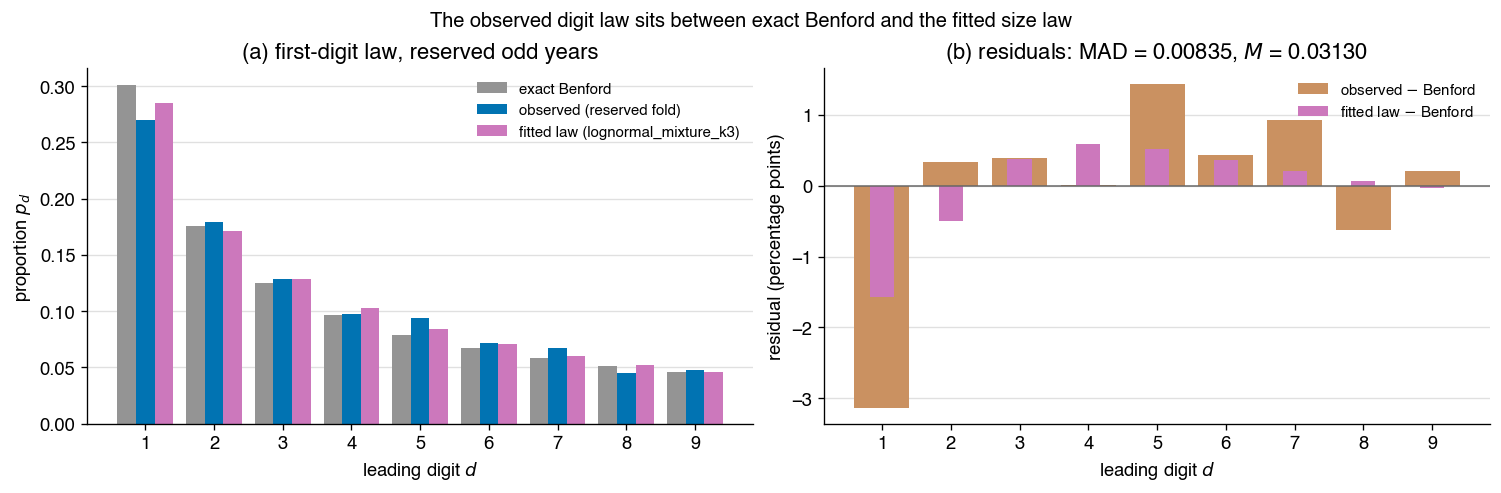

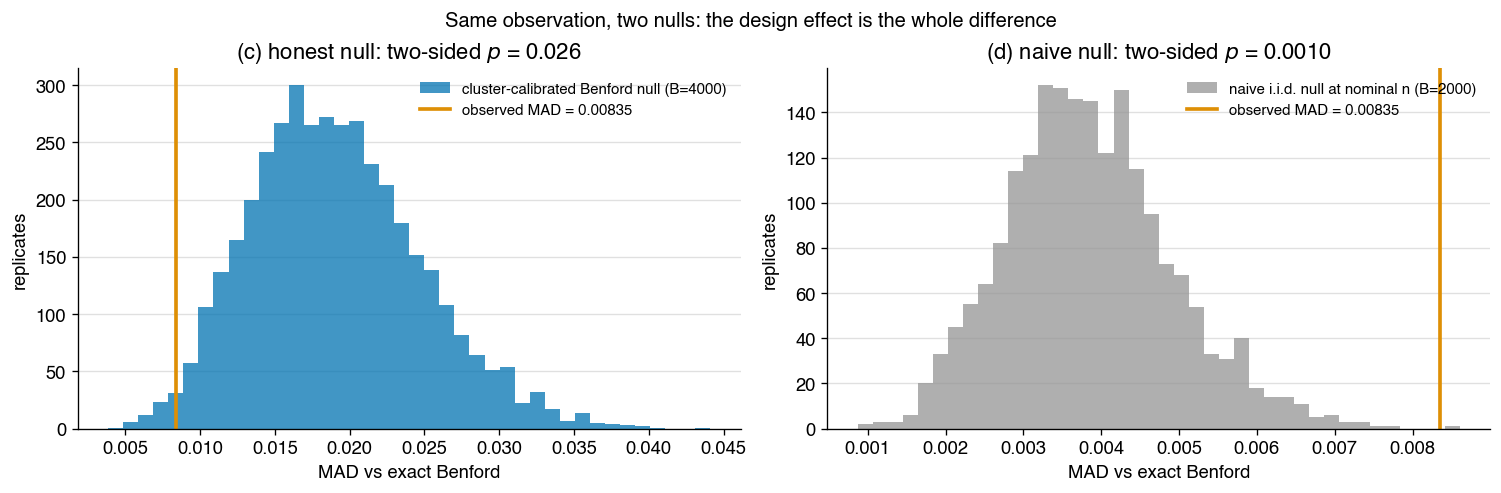

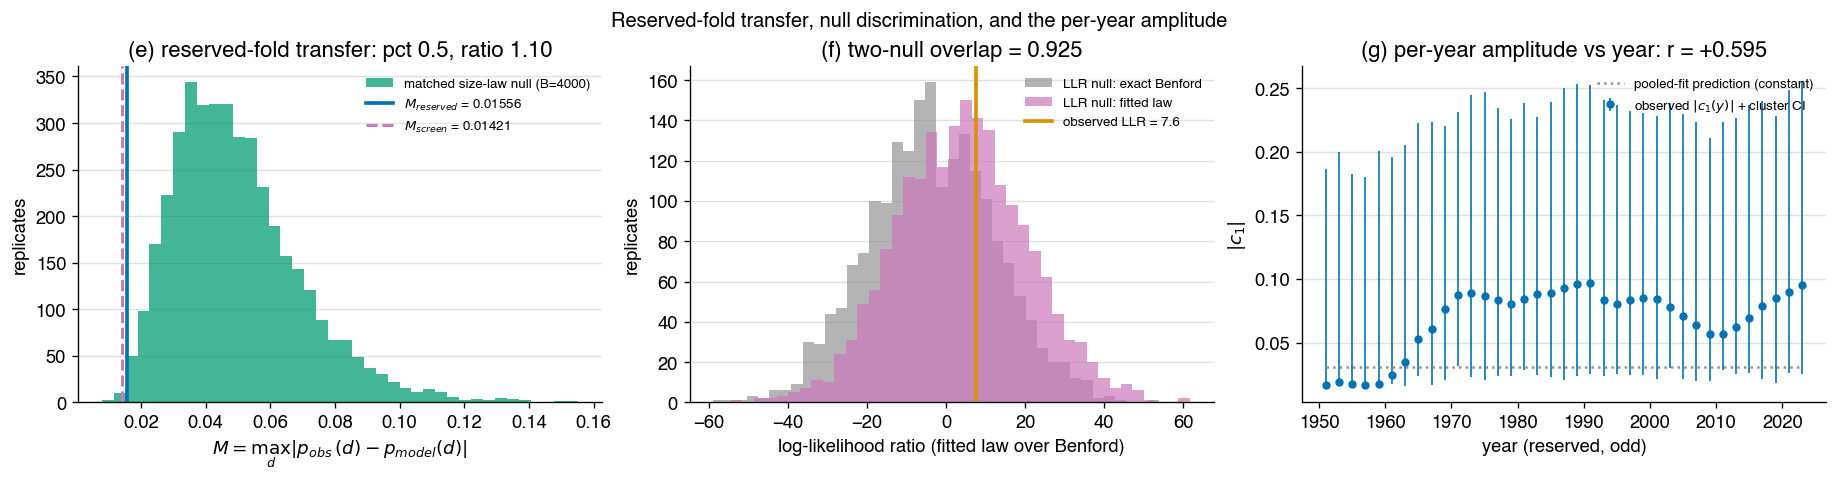

In [29]:
digits = np.arange(1, 10)
p_res = np.asarray(od["digit_proportions"], float)

# ---- figure 1: the digit law and its residuals -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0))

ax = axes[0]
w = 0.27
ax.bar(digits - w, BENFORD_P, width=w, color=COLOURS["baseline"], label="exact Benford")
ax.bar(digits, p_res, width=w, color=COLOURS["method"], label="observed (reserved fold)")
ax.bar(digits + w, p_model, width=w, color=COLOURS["other_1"], label=f"fitted law ({winner_name})")
ax.set_xticks(digits)
ax.set_xlabel("leading digit $d$")
ax.set_ylabel("proportion $p_d$")
ax.set_title("(a) first-digit law, reserved odd years")
ax.legend(loc="upper right", fontsize=9)

ax = axes[1]
ax.axhline(0.0, color="#666666", lw=0.9)
ax.bar(digits, 100.0 * (p_res - BENFORD_P), color=COLOURS["other_2"],
       label="observed $-$ Benford")
ax.bar(digits, 100.0 * (p_model - BENFORD_P), width=0.35, color=COLOURS["other_1"],
       label=f"fitted law $-$ Benford")
ax.set_xticks(digits)
ax.set_xlabel("leading digit $d$")
ax.set_ylabel("residual (percentage points)")
ax.set_title(f"(b) residuals: MAD = {cal_odd['MAD']['observed']:.5f}, "
             f"$M$ = {cal_odd['M']['observed']:.5f}")
ax.legend(loc="upper right", fontsize=9)

fig.suptitle("The observed digit law sits between exact Benford and the fitted size law", fontsize=12)
plt.show()

# ---- figure 2: the two MAD nulls, side by side -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0), sharex=False)

ax = axes[0]
cl = conf_cal_odd["_cluster_null"]["stats"][:, STAT_KEYS.index("MAD")]
ax.hist(cl, bins=40, color=COLOURS["method"], alpha=0.75,
        label=f"cluster-calibrated Benford null (B={B_CALIBRATED})")
ax.axvline(cal_odd["MAD"]["observed"], color=COLOURS["other_3"], lw=2.2,
           label=f"observed MAD = {cal_odd['MAD']['observed']:.5f}")
ax.set_xlabel("MAD vs exact Benford")
ax.set_ylabel("replicates")
ax.set_title(f"(c) honest null: two-sided $p$ = {cal_odd['MAD']['two_sided_p']:.3f}")
ax.legend(loc="upper right", fontsize=9)

ax = axes[1]
iid = conf_cal_odd["_iid_null"]["stats"][:, STAT_KEYS.index("MAD")]
ax.hist(iid, bins=40, color=COLOURS["baseline"], alpha=0.75,
        label=f"naive i.i.d. null at nominal n (B={B_IID})")
ax.axvline(cal_odd["MAD"]["observed"], color=COLOURS["other_3"], lw=2.2,
           label=f"observed MAD = {cal_odd['MAD']['observed']:.5f}")
ax.set_xlabel("MAD vs exact Benford")
ax.set_ylabel("replicates")
ax.set_title(f"(d) naive null: two-sided $p$ = "
             f"{conf_cal_odd['naive_iid_null']['MAD']['two_sided_p']:.4f}")
ax.legend(loc="upper right", fontsize=9)

fig.suptitle("Same observation, two nulls: the design effect is the whole difference", fontsize=12)
plt.show()

# ---- figure 3: reserved-fold transfer, discrimination, per-year amplitude --
fig, axes = plt.subplots(1, 3, figsize=(15.2, 3.9))

ax = axes[0]
ax.hist(null_law_odd["M"], bins=40, color=COLOURS["other_4"], alpha=0.75,
        label=f"matched size-law null (B={B_ENVELOPE})")
ax.axvline(conf["M_reserved"], color=COLOURS["method"], lw=2.2,
           label=f"$M_{{reserved}}$ = {conf['M_reserved']:.5f}")
ax.axvline(conf["M_screen"], color=COLOURS["other_1"], lw=1.8, ls="--",
           label=f"$M_{{screen}}$ = {conf['M_screen']:.5f}")
ax.set_xlabel("$M = \\max_d |p_{obs}(d) - p_{model}(d)|$")
ax.set_ylabel("replicates")
ax.set_title(f"(e) reserved-fold transfer: pct "
             f"{conf['M_matched_null_percentile']:.1f}, ratio "
             f"{conf['replication_attenuation_ratio']:.2f}")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
ax.hist(discr["_llr_null_benford"], bins=40, color=COLOURS["baseline"], alpha=0.7,
        label="LLR null: exact Benford")
ax.hist(discr["_llr_null_model"], bins=40, color=COLOURS["other_1"], alpha=0.7,
        label="LLR null: fitted law")
ax.axvline(discr["llr_observed"], color=COLOURS["other_3"], lw=2.2,
           label=f"observed LLR = {discr['llr_observed']:.1f}")
ax.set_xlabel("log-likelihood ratio (fitted law over Benford)")
ax.set_ylabel("replicates")
ax.set_title(f"(f) two-null overlap = "
             f"{discr['null_distributions_overlap_share']:.3f}")
ax.legend(loc="upper right", fontsize=8)

ax = axes[2]
# the percentile bootstrap interval of a modulus need not straddle the point estimate,
# so clip the bars at zero rather than letting matplotlib reject a negative yerr
err_lo = np.maximum(py.abs_c1_observed - py.abs_c1_ci_low, 0.0)
err_hi = np.maximum(py.abs_c1_ci_high - py.abs_c1_observed, 0.0)
ax.errorbar(py.year, py.abs_c1_observed,
            yerr=[err_lo, err_hi],
            fmt="o", color=COLOURS["method"], ms=4, lw=1.0,
            label="observed $|c_1(y)|$ + cluster CI")
ax.plot(py.year, np.full(len(py), abs(c_from_digits(p_model, 1))),
        color=COLOURS["baseline"], ls=":", lw=1.5,
        label="pooled-fit prediction (constant)")
ax.set_xlabel("year (reserved, odd)")
ax.set_ylabel("$|c_1|$")
ax.set_title(f"(g) per-year amplitude vs year: r = {year_trend['stat']:+.3f}")
ax.legend(loc="upper right", fontsize=8)

fig.suptitle("Reserved-fold transfer, null discrimination, and the per-year amplitude", fontsize=12)
plt.show()

## 21. What these results say

Read this section against the table in §19 — every claim below refers to a printed number, and the
table gives the full-artifact value beside each one, so it is visible where the 100-country demo agrees
and where it does not.

**1. The two nulls disagree, and *that disagreement* is the finding.**
The observed digit law is not exact Benford in the descriptive sense: MAD around 0.008, $\chi^2$ in the
low thirties on 8 degrees of freedom, $|c_1| \approx 0.06$ with a phase near $-93^\circ$, and per-digit
residuals of a couple of percentage points. Under the **naive i.i.d. null** every one of the five
readouts is rejected at $p \lesssim 0.001$ — that is the test a nominal-$n$ spreadsheet $\chi^2$ performs,
and it is what the population-digit literature reports. Under the **cluster-calibrated** null the same
numbers are ordinary: $p$ is 0.03 (MAD), 0.37 ($M$), 0.66 ($|c_1|$), 0.02 ($\chi^2$), 0.11 (Kuiper). The
whole difference is the single number printed in §10: the **design effect**, 9.1 here and 8.94 in the
full run. With an ICC of 0.23 and 74 years per country, the effective sample size is ~406, not 3,700 —
so the naive $p$-value is an artefact of counting near-replicated countries as independent draws.

A caveat the demo makes visible rather than hides: at 100 countries the per-readout $p$-values are
noisier than at 236, and here two of the five (MAD, $\chi^2$) fall just below the 2.5th percentile of the
cluster null, so the "inside the envelope on all five" statement that holds for the full panel does
**not** hold verbatim at this sample size. The correct reading of the demo is the *contrast*: the naive
null rejects everything by orders of magnitude, the cluster-calibrated null mostly does not (3 of 5
readouts inside its 95% envelope, and the two that fall outside do so at $p \approx 0.02\text{–}0.03$, not
$10^{-4}$). That contrast is what the artifact's headline rests on, and it survives the shrink from 236
to 100 countries (8,732 → 3,700 reserved rows) intact.

**2. The digits cannot discriminate a size mechanism from Benford at all.**
The BIC-winning law is the three-component lognormal mixture, and its own digit law sits within
MAD ≈ 0.005 of exact Benford — closer than any 100- or 236-country sample could resolve. The
discrimination panel shows the consequence: the simulated log-likelihood-ratio distributions
**overlap on ~0.92 of their support**, and the observed LLR sits comfortably inside both ($p = 0.24$
against Benford, $p = 0.59$ against the fitted law). Being unremarkable under *both* nulls is not a
contradiction; it means the data live in the overlap of two near-identical predictions. "These digits
follow Benford" is therefore not evidence for a specific demographic mechanism, because the mechanism
predicts almost exactly the same digits. That indistinguishability is the sharper form of the negative.

**3. The reserved-fold transfer measures the *fit*, not a Benford departure.**
$M_{reserved}$ (0.016) is well under the 0.05 margin and the attenuation ratio is 1.10, so the even-fold
law carries to the odd years. But its matched-null percentile is 0.5 — the extreme lower edge of the
envelope — so the pre-registered three-part conjunction (`percentile ∈ [2.5, 97.5]`) fails and the demo
prints **NOT CONFIRMED** where the full run printed SURVIVOR CONFIRMED (at percentile 3.55, itself near
the band edge). This is the artifact's own documented limit, reproduced faithfully: the confirmation
rests on a two-sided band whose lower edge is a knife-edge at these sample sizes, and at 100 countries
the fit is so tight relative to the null that it falls off the bottom of the band. Note what the
statistic does and does not say — a good fit to the size law and a good fit to Benford are
simultaneously true here, because the two laws are nearly the same law on the digit scale.

**4. Reporting grain and scale do not explain the signal.**
Rounding to 3 significant figures moves the projected residual by only ~4% of its size; rounding to the
nearest 1,000 moves it ~34%, both below the 0.5 limit, so the demographic account survives. (The full
run's 5.8% for the same check is smaller because its 236-country sample contains proportionally fewer
microstates.) The scale-rotation identity holds to machine precision in every case — the phase rotates
by exactly $360\log_{10}c$ and the modulus does not move, which a numerical artefact would not do.
The projected-residual sign across population floors is **not** stable at this sample size (§18 prints
which floors flip), which is one more honest demo-vs-full-run difference: the full panel's stability
comes from having both more countries and, proportionally, more large ones.

**5. The per-year amplitude evidence is trend-only, and here it disagrees in sign.**
The demo's $|c_1(y)|$ correlates $+0.60$ with calendar year (block-bootstrap CI straddling zero) where the
full run reports $-0.72$. With 37 reserved years of 100 countries each, a single correlation has wide
error bars and neither sign should be treated as a finding. The point the cell makes is structural, not
numeric: a pooled fit's first harmonic is attenuated to $\exp(-2\pi^2\sigma^2)\approx 3\times10^{-2}$ here
($3\times10^{-5}$ in the full run), so a pooled prediction cannot serve as the per-year predictor — each
year's *own* fitted law must be, exactly as the artifact's fixed defect #3 records.

### What to scale for the full run

The full artifact uses the whole panel (236 countries × 74 years) with `B_CALIBRATED = 10_000`,
`B_ENVELOPE = 4_000`, `B_IID = 2_000`, `B_DISCRIM = 5_000` and `N_RESTARTS = 20`; it also adds the
narrow-component ablation suite, the year-specific law fit for every year, the entity-disjoint
sensitivity check and the WDI/OWID source-invariance audit, omitted here to stay inside a few minutes of
CPU time. Raising the four `B_*` constants and `N_RESTARTS` in the config cell is a one-line change and
tightens the $p$-values; adding countries is what tightens the *statistical* statements, and the
full-panel reference column shows what that buys.

**What the artifact fixed in its own instrument** (each visible in the code above): $\chi^2$ and Kuiper
$V$ now share the reference vector with the residuals; the rounding simulation measures the *change*
rounding makes rather than a tautological ratio of ~1; the per-year predictor is a year-specific law, not
a constant; Kuiper $V$ has a reference distribution; the naive i.i.d. null is drawn from a **uniform
mantissa** (which *is* exact Benford) rather than the uniform-**digit** law $\log_{10}(1+9u)$ — and
`sampler_self_test` checks that at every run, aborting if it is backwards.